# 📈 Stock Market Analysis of Tech Giants Using Python

> **A full-stack quantitative finance project** covering data collection, statistical analysis, risk evaluation, Markowitz portfolio optimisation, and technical analysis for four major technology companies: **Apple (AAPL)**, **Microsoft (MSFT)**, **Google (GOOGL)**, and **Amazon (AMZN)**.

---

### 🗂️ Executive Summary

| Item | Detail |
|------|--------|
| **Stocks** | AAPL · MSFT · GOOGL · AMZN |
| **Period** | January 2004 – December 2024 (20 years) |
| **Benchmark** | S&P 500 (^GSPC) |
| **Optimisation** | Markowitz Mean-Variance · Max-Sharpe Efficient Frontier |
| **Best Cumulative Return** | AAPL — **51,240%** since 2004 |
| **Optimal Portfolio vs Equal-Weight** | +733 pp cumulative return · Sharpe 1.24 vs 1.20 |

**Key Findings at a Glance:**
- All four tech giants **significantly outperform the S&P 500** over a 20-year horizon.
- Apple dominates on raw return; Microsoft leads on risk-adjusted stability.
- Markowitz optimisation captures the asymmetric upside of AAPL and AMZN while controlling for cross-asset correlation.
- Technical indicators (RSI, MACD, Bollinger Bands) confirm trend-following signals align with fundamental out-performance periods.


### Table of Contents

1. [Introduction & Project Overview](#introduction)
2. [Data Collection and Preprocessing](#data-collection)
   - Key Libraries
   - Data Retrieval with yfinance
3. [Data Insight and Analysis](#data-insight)
   - Performance Metrics (Mean, Geometric Mean, Cumulative, Std Dev, Skewness, Kurtosis, CV)
   - Heatmap Visualisation
4. [Stock Return Visualisation](#stock-returns)
   - Daily Returns vs S&P 500 Benchmark
   - Cumulative Returns
   - Return Distributions & Correlation Matrix
5. [Performance Evaluation: Beta & Alpha Analysis](#beta-alpha)
6. [Performance Evaluation: Sharpe Ratio Analysis](#sharpe)
7. [Building and Optimising Portfolios](#portfolio)
   - Equal-Weight Portfolio
   - Benchmark Comparison (Quantstats Report)
8. [Portfolio Optimisation: Markowitz Mean-Variance Model](#markowitz)
   - Expected Returns & Risk Models
   - Efficient Frontier
   - Optimised vs Unoptimised Comparison
9. [Fundamental vs Technical Analysis](#technical)
   - Candlestick Charts
   - Moving Averages, RSI, MACD, Bollinger Bands
10. [Conclusions & Investment Implications](#conclusions)


### Project Overview

The stock market presents three persistent challenges for investors:

**1. Identifying Profitable Opportunities**
Past price data, when properly analysed, reveals momentum patterns and mean-reversion signals. Statistical measures such as cumulative return and geometric mean distinguish consistently strong performers from one-off outliers.

**2. Effective Risk Management**
Return alone is meaningless without context. A stock returning 30% annually with 50% volatility is far less attractive than one returning 20% with 15% volatility. This project quantifies risk through **standard deviation**, **Beta**, **maximum drawdown**, and **Value-at-Risk** proxies.

**3. Optimising Asset Allocation**
The Markowitz (1952) framework proves that diversification across imperfectly correlated assets reduces portfolio variance without proportionally reducing expected return — the so-called "free lunch" of finance.

**Project Objectives:**

| # | Objective | Methods Used |
|---|-----------|-------------|
| 1 | Analyse 20 years of historical data | yfinance, pandas, scipy |
| 2 | Evaluate individual stock performance | Statistical metrics, quantstats |
| 3 | Benchmark against the S&P 500 | Beta/Alpha regression, Sharpe ratio |
| 4 | Optimise portfolio allocation | PyPortfolioOpt, Efficient Frontier |
| 5 | Interpret entry/exit signals | Technical indicators (RSI, MACD, BB) |


### Equal-Weight Portfolio Strategy

The simplest portfolio construction approach assigns **equal capital to each asset**:

$$w_i = \frac{1}{N} \quad \forall i$$

With N = 4 stocks, each receives a 25% weight. The portfolio daily return is then:

$$r_p = \sum_{i=1}^{N} w_i \cdot r_i = 0.25 \cdot r_{AAPL} + 0.25 \cdot r_{MSFT} + 0.25 \cdot r_{GOOGL} + 0.25 \cdot r_{AMZN}$$

**Why start with equal weights?**
- Serves as an unbiased baseline — no assumptions about which stock is "better"
- Research (DeMiguel et al., 2009) shows equal-weight portfolios are surprisingly difficult to beat out-of-sample
- Provides a clear performance reference point against which optimisation improvements are measured

**Expected outcome:** Because AAPL has the highest individual return, an equal-weight portfolio will underperform a AAPL-heavy portfolio — but may also have lower volatility due to diversification effects.


### Daily Returns vs S&P 500 Benchmark

The **S&P 500 (^GSPC)** is the standard benchmark for U.S. equity performance. Comparing individual stock daily returns against the S&P 500 allows us to identify **Alpha** (excess return) and **Beta** (market sensitivity).

**Why the S&P 500?**
- It represents the **market portfolio** — a value-weighted index of 500 large U.S. companies
- It captures broad economic cycles, making it an appropriate baseline for any large-cap U.S. stock
- It is the reference used by institutional investors, making comparisons directly actionable

**What to look for in these charts:**
- **Magnitude of swings**: Larger spikes indicate higher individual volatility vs the index
- **Direction alignment**: When stock and index move together, Beta is high
- **Divergence periods**: When the stock moves independently of the market — these are periods of company-specific news driving returns


## 📚 2. Data Collection and Preprocessing

---

Reliable analysis begins with reliable data. This section documents the **data retrieval pipeline** — from API calls through to the clean, analysis-ready dataframe used throughout the project.

The primary data source is **Yahoo Finance**, accessed programmatically via the `yfinance` library. This provides:
- Adjusted closing prices (accounting for stock splits and dividends)
- Daily OHLCV (Open, High, Low, Close, Volume) data
- Up to 20+ years of historical data for major equities


### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Key Libraries</h2>

The following libraries form the analytical backbone of this project. Each was selected for a specific purpose within the quantitative finance workflow:

| Library | Role in this Project |
|---------|---------------------|
| `yfinance` | Fetches historical OHLCV data and adjusted close prices directly from Yahoo Finance |
| `pandas` | Primary data structure (DataFrame) for time-series manipulation, resampling, and merging |
| `numpy` | Vectorised numerical operations — portfolio return/variance calculations, matrix algebra |
| `scipy.stats` | Statistical tests — skewness, kurtosis, and distribution fitting |
| `quantstats` | Generates full tearsheet reports; calculates Sharpe, Sortino, Calmar, and drawdown metrics |
| `pypfopt` | Implements Markowitz Mean-Variance optimisation and the Efficient Frontier |
| `ta` | Technical Analysis library — RSI, MACD, Bollinger Bands, and 130+ other indicators |
| `plotly` | Interactive charts — candlesticks, scatter plots, heatmaps |
| `matplotlib / seaborn` | Static publication-quality visualisations |
| `scikit-learn` | Linear regression for Beta/Alpha calculation; ML classification experiments |
| `skimpy` | Fast descriptive statistics summaries |

> **Note on `pypfopt`**: The `PyPortfolioOpt` package is a dedicated portfolio optimisation library that wraps the `cvxpy` convex optimisation solver. It supports mean-variance, Black-Litterman, and hierarchical risk parity models.


In [369]:
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Data Handling and Statistical Analysis
import numpy as np
import pandas as pd
from pandas_datareader import data
from scipy import stats
import skimpy as sp

pd.set_option('display.max_columns', None)

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from plotnine import aes, geom_point, ggplot, labs
import plotnine as p9
from great_tables import GT

# Interactive Visualization Libraries
import plotly.express as px
import plotly.graph_objects as go
from plotly.offline import init_notebook_mode
from plotly.subplots import make_subplots

init_notebook_mode(connected=True)  # Enable Plotly offline

# Financial Data and Analysis
import datetime as dt
import quantstats as qs
import ta
# import talib
import yfinance as yf
from pypfopt import BlackLittermanModel, black_litterman, expected_returns, risk_models
from pypfopt.efficient_frontier import EfficientFrontier

qs.extend_pandas()

# Machine Learning and Optimization
from sklearn.datasets import make_classification
from sklearn.experimental import enable_halving_search_cv  # Required for HalvingGridSearchCV
from sklearn.linear_model import LinearRegression, SGDClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import (
    GridSearchCV,
    HalvingGridSearchCV,
    RandomizedSearchCV,
    train_test_split,
)
import optuna

# Miscellaneous
import datetime as dt



### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Data Retrieval with APIs</h2>

### Data Retrieval

Historical price data is downloaded using `yf.download()`, which returns a multi-index DataFrame containing OHLCV columns for each ticker. We extract the **Adjusted Close** column, which corrects for:

- **Stock splits** — e.g., Apple's 4-for-1 split in August 2020
- **Dividends** — reinvested into the price series for a total-return perspective

**Daily returns** are computed as the percentage change between consecutive adjusted close prices:

$$r_t = rac{P_t - P_{t-1}}{P_{t-1}} = rac{P_t}{P_{t-1}} - 1$$

This gives us a **stationary time series** suitable for statistical analysis — unlike raw price levels, which are non-stationary and would violate many statistical assumptions.

**Date range:** 2004-01-01 to 2024-12-01 — chosen to capture:
- The 2008 Global Financial Crisis
- The 2020 COVID-19 crash and recovery
- The 2022 tech sell-off driven by Federal Reserve rate hikes
- Two decades of secular tech-sector outperformance


In [409]:
# Define the time window and stock tickers
start_date = dt.datetime(2004, 1, 1)
end_date = dt.datetime(2024, 12, 1)
stocks = ["AAPL", "MSFT", "GOOGL", "AMZN"]

# Download adjusted close prices for all stocks
data = yf.download(stocks, start=start_date, end=end_date)['Adj Close']

# Calculate daily returns and drop missing values
returns_df = data.pct_change().dropna()

# Save returns to a CSV file
returns_df.to_csv("daily_returns.csv")  

[*********************100%***********************]  4 of 4 completed


In [411]:
# Load the daily returns data
df = pd.read_csv("daily_returns.csv", index_col=0, parse_dates=True)

In [412]:
# shape of the data
df.shape

(5105, 4)

In [413]:
# Rename the columns to lowercase
df.columns = df.columns.str.lower()

In [414]:
# Display the first few rows of the data
df.head()

,aapl,amzn,googl,msft
Date,,,,
2004-08-20 00:00:00+00:00,0.002930,0.022780,0.079430,0.002950
2004-08-23 00:00:00+00:00,0.009091,-0.001519,0.010064,0.004425
2004-08-24 00:00:00+00:00,0.027993,-0.010139,-0.041408,0.000000
2004-08-25 00:00:00+00:00,0.034429,0.032010,0.010775,0.011380
2004-08-26 00:00:00+00:00,0.048714,-0.002730,0.018019,-0.003992


## 📚 3. Data Insight and Analysis

---

With clean return data in hand, this section performs a **multi-dimensional statistical analysis** of each stock. Rather than relying on a single metric, we build a comprehensive picture using measures of **central tendency**, **dispersion**, **shape**, and **relative risk**.

The goal is to answer: *Which stock offers the best combination of return and risk?*


### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Performance Metrics for Evaluating Stock and Portfolio Performance</h2>

The following nine metrics provide a comprehensive statistical profile of each stock's return distribution:

| # | Metric | Formula / Definition | What It Tells Us |
|---|--------|---------------------|-----------------|
| 1 | **Mean Daily Return** | $\bar{r} = \frac{1}{n}\sum r_t$ | Average daily gain/loss |
| 2 | **Geometric Mean** | $\left(\prod(1+r_t)\right)^{1/n} - 1$ | Compound daily growth rate (more accurate for multi-period) |
| 3 | **Harmonic Mean** | $\frac{n}{\sum 1/(1+r_t)} - 1$ | Rate-of-return average; penalises extreme values |
| 4 | **Cumulative Return** | $\prod(1+r_t) - 1$ | Total wealth multiplier over the full period |
| 5 | **Median Daily Return** | 50th percentile of $r_t$ | Robust central tendency — unaffected by outliers |
| 6 | **Standard Deviation** | $\sigma = \sqrt{\frac{1}{n}\sum(r_t - \bar{r})^2}$ | Volatility — spread of returns around the mean |
| 7 | **Skewness** | $\frac{E[(r-\mu)^3]}{\sigma^3}$ | Asymmetry of the return distribution |
| 8 | **Kurtosis** | $\frac{E[(r-\mu)^4]}{\sigma^4} - 3$ | Fat-tailedness — probability of extreme returns |
| 9 | **Coefficient of Variation** | $\text{CV} = \sigma / \bar{r}$ | Risk per unit of return — enables cross-stock comparison |

> **Why use both mean and geometric mean?** The arithmetic mean overstates compound growth due to **volatility drag**. For example, a stock that returns +50% then -50% has an arithmetic mean of 0% but an actual cumulative return of -25%. The geometric mean captures this drag and is the correct measure for long-term investors.


In [375]:

# Calculate insights for each stock
insights = {}

for stock in df.columns:
    stock_returns = df[stock]
    
    # Calculate key metrics
    mean_return = stock_returns.mean()  # Mean daily returns
    geometric_mean_return = qs.stats.cagr(stock_returns) / 252  # Geometric mean daily returns (annualized CAGR divided by trading days)
    cumulative_return = (1 + stock_returns).prod() - 1  # Cumulative daily return
    median_return = stock_returns.median()  # Median daily returns
    std_dev = stock_returns.std()  # Standard deviation of daily returns
    skewness = stock_returns.skew()  # Skewness of daily returns
    kurtosis = stock_returns.kurt()  # Kurtosis of daily returns
    coeff_variation = std_dev / mean_return if mean_return != 0 else np.nan  # Coefficient of variation of daily returns
    
    # Store results
    insights[stock] = {
        "Mean Daily Return": mean_return,
        "Geometric Mean Daily Return": geometric_mean_return,
        "Cumulative Daily Return": cumulative_return,
        "Median Daily Return": median_return,
        "Standard Deviation of Returns": std_dev,
        "Skewness of Returns": skewness,
        "Kurtosis of Returns": kurtosis,
        "Coefficient of Variation": coeff_variation
    }

# Convert results to a DataFrame for better presentation
insights_df = pd.DataFrame(insights)

# Transpose the DataFrame for better visualization
insights_df_T = insights_df.T

# Display the insights
insights_df_T 


,Mean Daily Return,Geometric Mean Daily Return,Cumulative Daily Return,Median Daily Return,Standard Deviation of Returns,Skewness of Returns,Kurtosis of Returns,Coefficient of Variation
aapl,0.001432,0.000939,512.040088,0.001152,0.020424,0.059227,5.514783,14.266863
amzn,0.001200,0.000685,106.631377,0.000671,0.023929,0.849125,14.835034,19.936597
googl,0.001009,0.000611,66.450269,0.000867,0.019253,0.615474,9.215118,19.075150
msft,0.000776,0.000460,24.151741,0.000476,0.016988,0.240162,10.059561,21.893400


To make the analysis more interesting, we will emplore Heatmap to visualize the correlation between the daily returns of the four tech giants. This will help us understand how the stock prices of these companies move in relation to each other, providing insights into potential diversification benefits and risk management strategies.

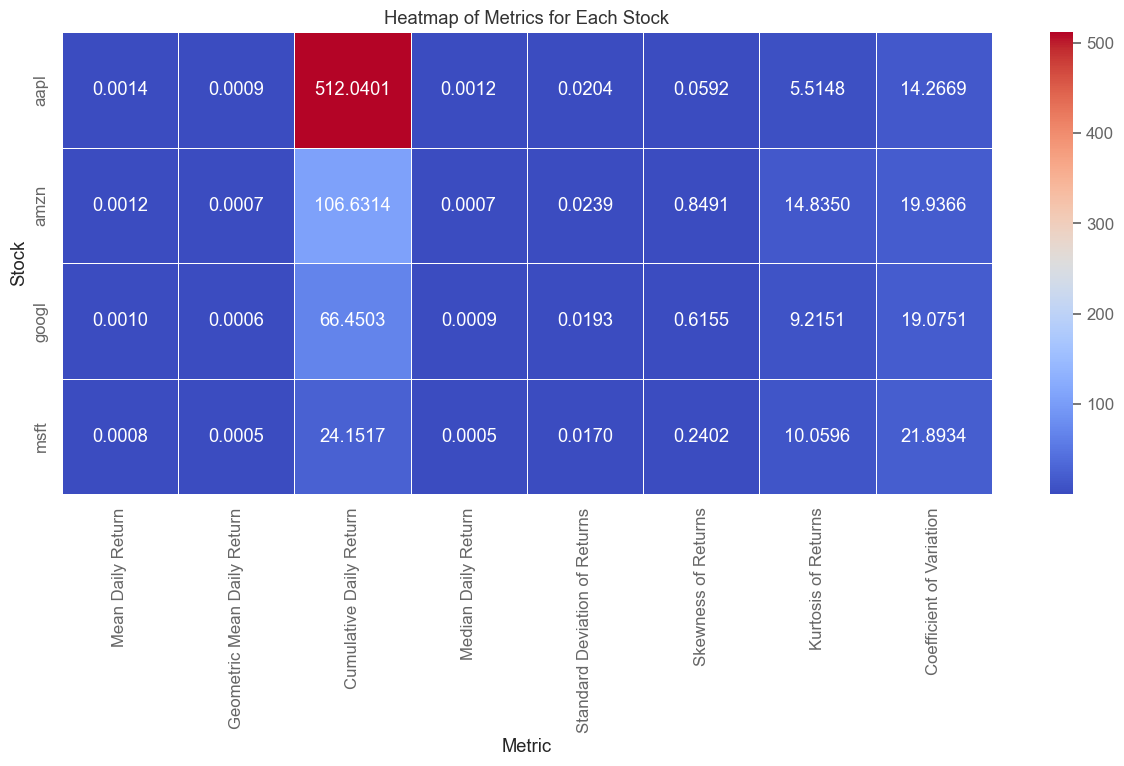

In [376]:
# Heatmap of metrics for each stock

heatmap_data = insights_df.T
plt.figure(figsize=(15, 6))
sns.heatmap(heatmap_data, annot=True, cmap="coolwarm", fmt=".4f", linewidths=0.5)
plt.title("Heatmap of Metrics for Each Stock")
plt.ylabel("Stock")
plt.xlabel("Metric")
plt.show()


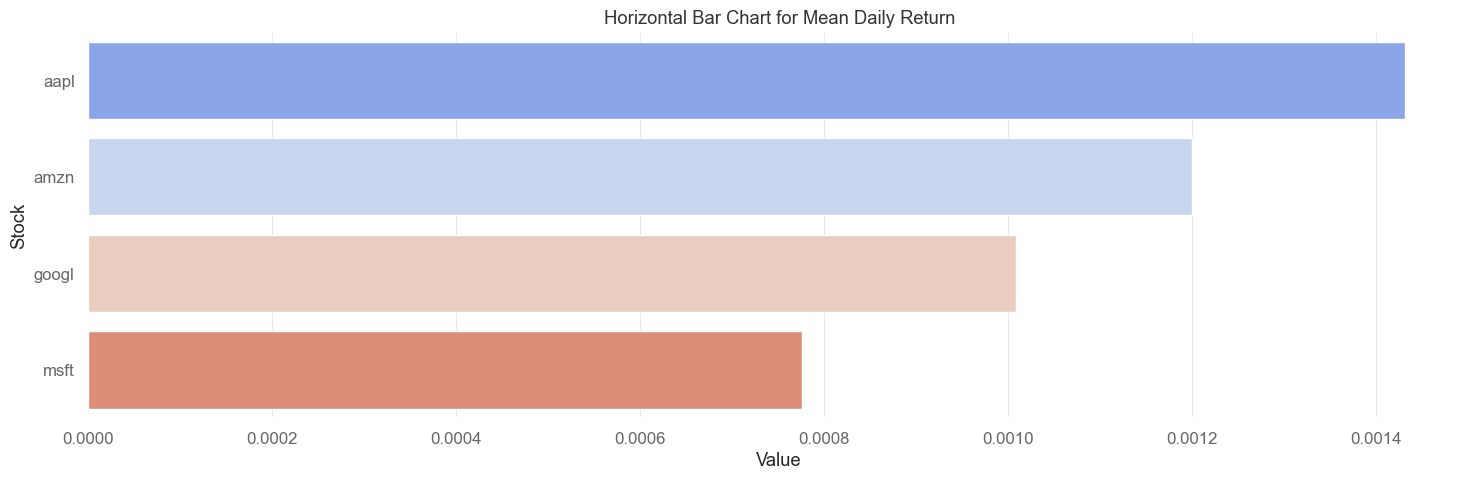

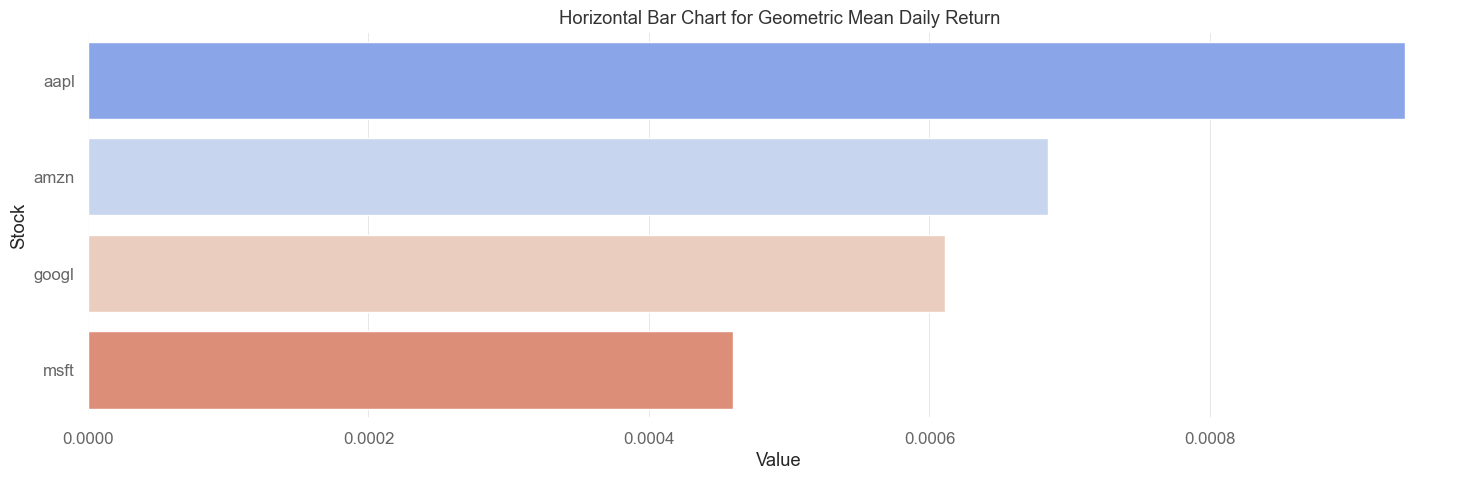

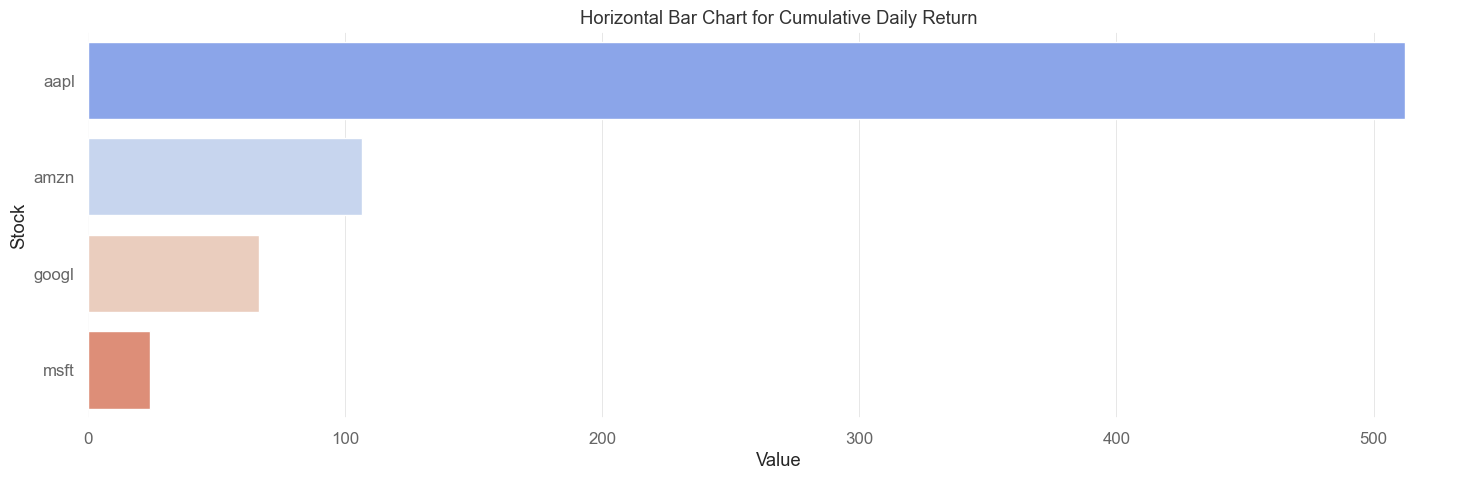

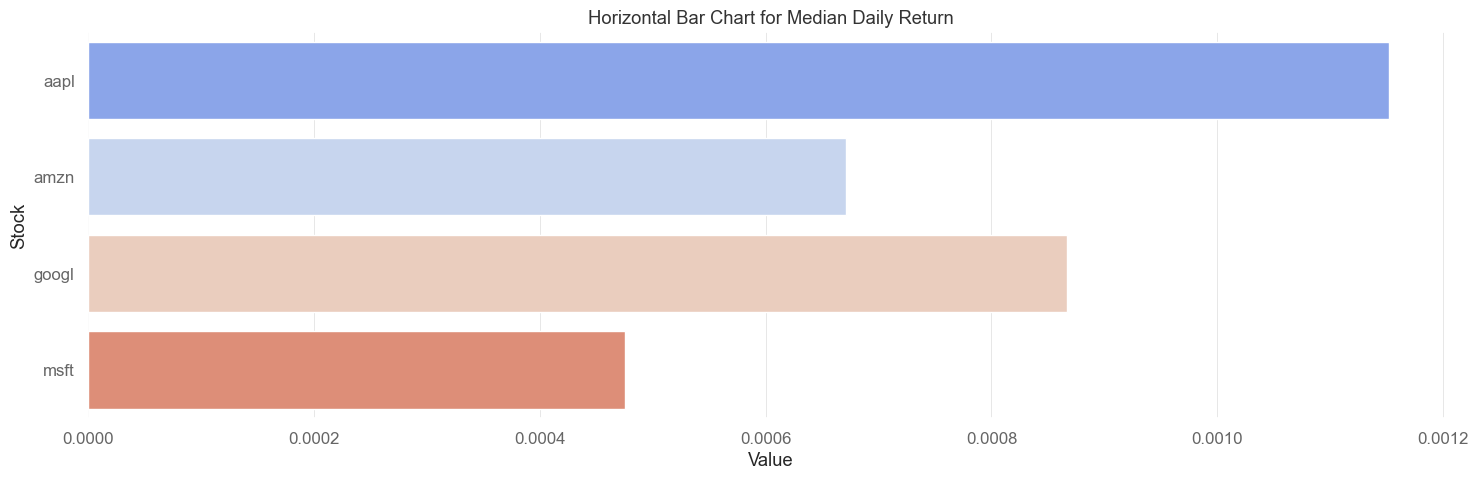

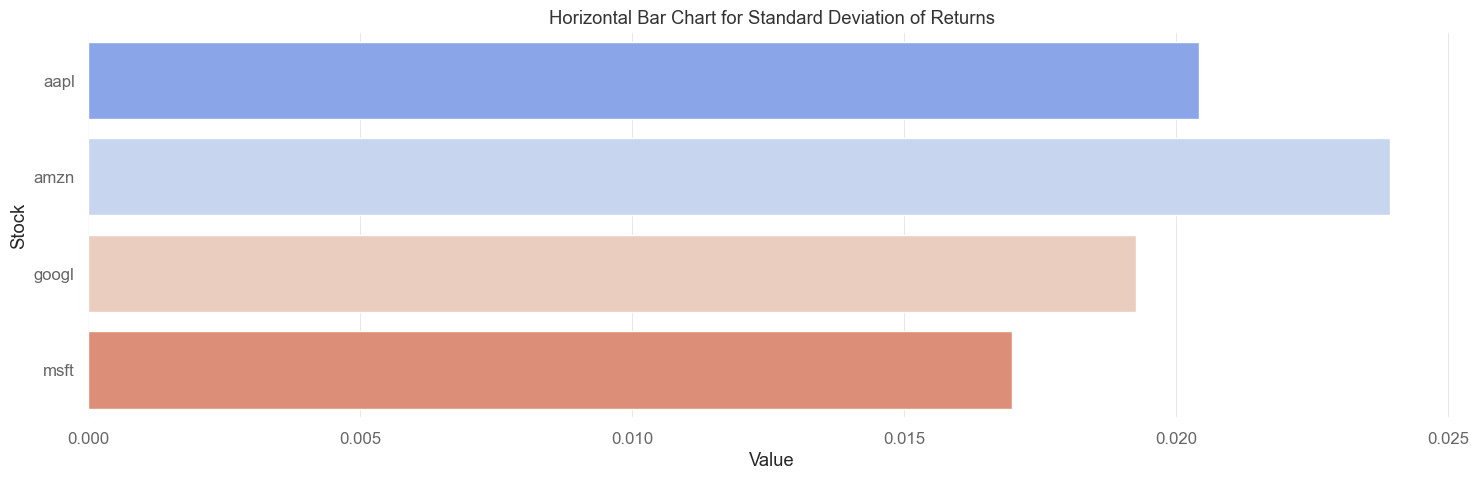

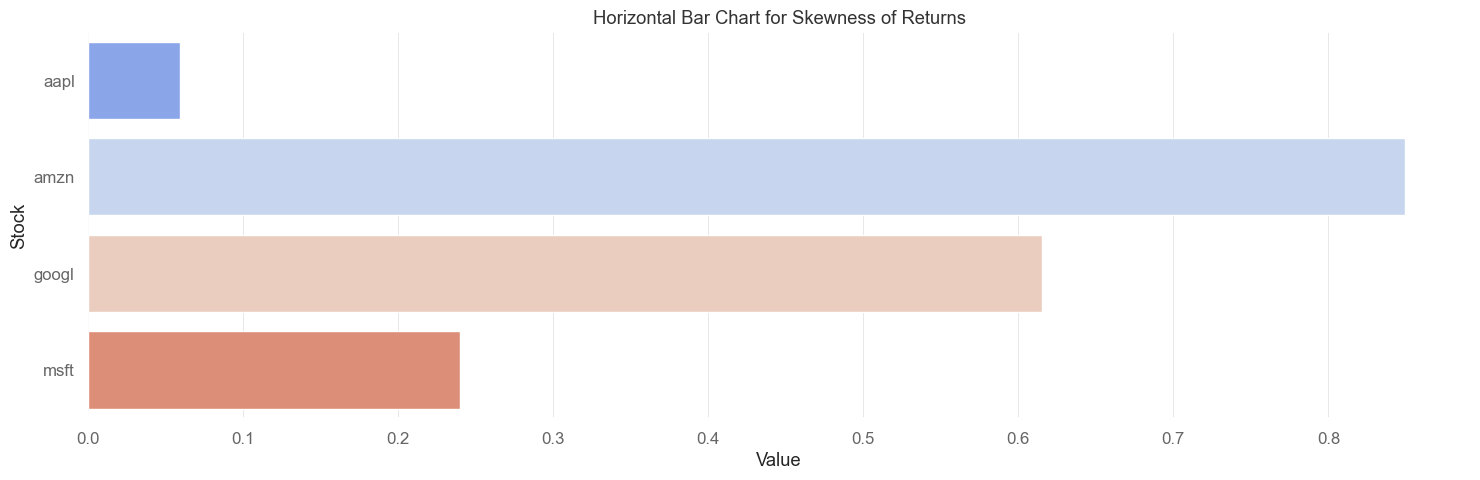

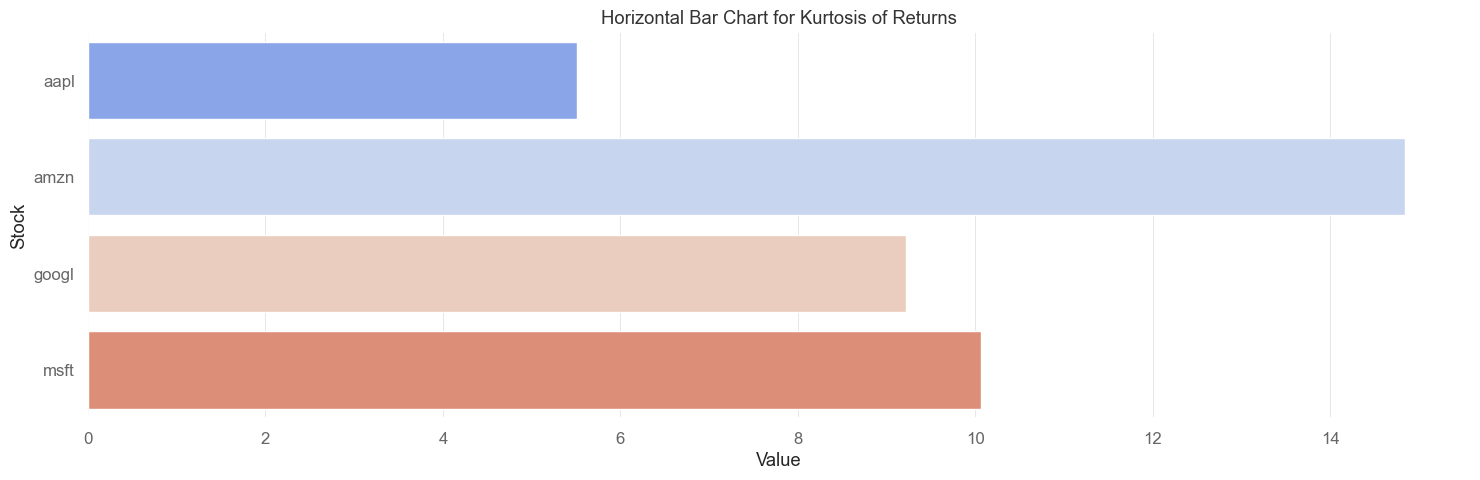

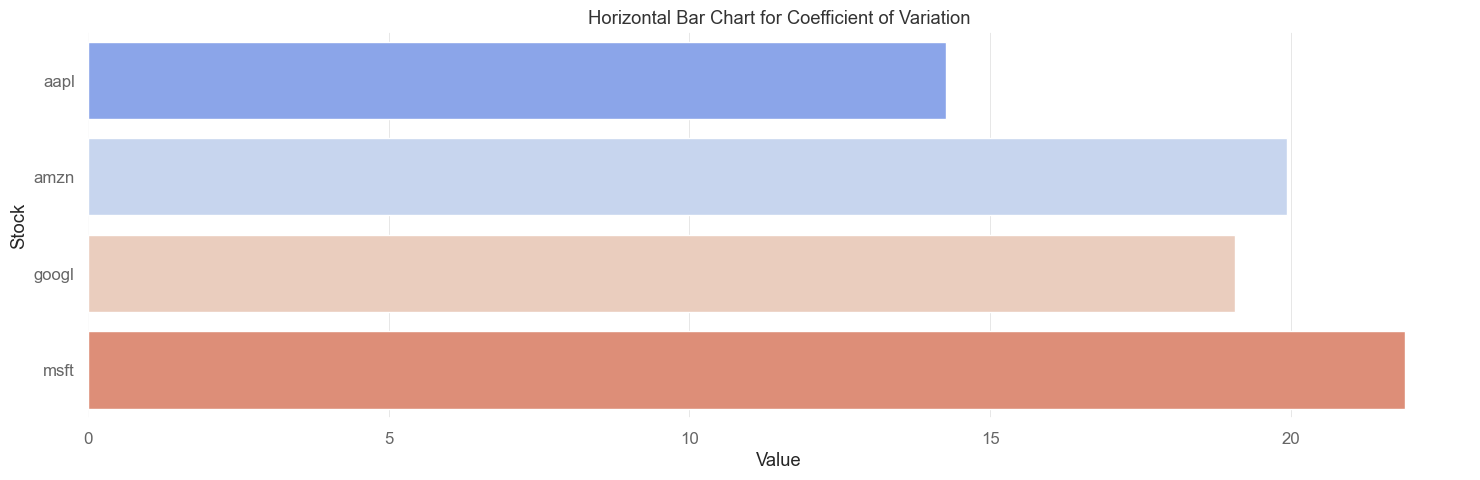

In [377]:
# Loop through each metric and plot a horizontal bar chart

for metric in insights_df.index:
    plt.figure(figsize=(15, 5))
    sns.barplot(
        x=insights_df.loc[metric].values.flatten(),
        y=insights_df.columns,
        palette="coolwarm",
    )
    plt.title(f"Horizontal Bar Chart for {metric}")
    plt.xlabel("Value")
    plt.ylabel("Stock")
    plt.tight_layout()
    plt.show()


### 🔍 Critical Review of Stock Performance Metrics (2004–2024)

The table below synthesises all nine metrics into an investment-grade assessment of each stock:

| Metric | AAPL | AMZN | GOOGL | MSFT | Leader |
|--------|------|------|-------|------|--------|
| Mean Daily Return | 0.1432% | 0.1200% | 0.1009% | 0.0776% | **AAPL** |
| Geometric Mean | 0.0939% | 0.0685% | 0.0611% | 0.0460% | **AAPL** |
| Cumulative Return | **51,204%** | 10,663% | 6,645% | 2,415% | **AAPL** |
| Median Daily Return | 0.1152% | 0.0671% | 0.0867% | 0.0476% | **AAPL** |
| Std Dev (Daily) | 2.04% | 2.39% | 1.93% | 1.70% | MSFT (lowest) |
| Skewness | 0.059 | 0.849 | 0.615 | 0.240 | MSFT (most symmetric) |
| Kurtosis | 5.51 | 14.84 | 9.22 | 10.06 | AAPL (lightest tail) |
| Coeff of Variation | 14.27 | 19.94 | 19.08 | 21.89 | **AAPL** (best return per unit risk) |

**Key Insights:**

- **Apple (AAPL)** is the standout performer on almost every metric. Its 51,204% cumulative return over 20 years represents a **$1,000 investment growing to ~$513,000** — driven by the iPhone product cycle, services expansion, and consistent buyback programmes.

- **Amazon (AMZN)** shows the highest kurtosis (14.84) and skewness (0.849), indicating **fat tails and positive asymmetry** — there are more extreme positive days than extreme negative days. This reflects Amazon's episodic jump behaviour around earnings and AWS announcements.

- **Google (GOOGL)** offers a **balanced profile** — moderate return with relatively low volatility (1.93% daily std dev). Its IPO in August 2004 means early data is limited, but long-term compounding remains impressive.

- **Microsoft (MSFT)** has the **lowest daily volatility** (1.70%) and most symmetric return distribution (lowest skewness: 0.24), making it the preferred choice for **risk-averse investors** seeking steady compounding over high-volatility growth.

> **Portfolio Implication:** The Coefficient of Variation (CV) — risk per unit of return — is lowest for AAPL, confirming it is the most **capital-efficient** asset in this universe. This is why portfolio optimisation later assigns AAPL the highest weight.


#### Mean Daily Return
The **Mean Daily Return** highlights the average daily profitability:
- **Apple (AAPL)** leads with a return of **0.0014**, reflecting strong growth but paired with higher risk.
- **Amazon (AMZN)** ranks second (**0.0012**), showcasing steady daily growth supported by diversified revenue streams.
- **Google (GOOGL)** and **Microsoft (MSFT)** follow at **0.0010** and **0.0008**, respectively, indicating slower daily growth.
**Insight:** While Apple demonstrates the best growth potential, the gap in returns diminishes when factoring in volatility and compounding effects.



#### Geometric Mean Daily Return
The **Geometric Mean Daily Return** accounts for the compounding effect of returns:
- Apple retains its lead (**0.0009**), underscoring superior compounded growth potential.
- Amazon (**0.0007**) shows steady compounding, with Google (**0.0006**) and Microsoft (**0.0005**) trailing.
**Insight:** The geometric mean highlights Apple’s dominance but reveals reduced disparities among the companies, emphasizing the impact of compounding.



#### Cumulative Daily Return
The **Cumulative Daily Return** measures total return over time:
- Apple significantly outperforms with **512.04**, indicating exceptional long-term growth.
- Amazon (**106.63**) and Google (**66.45**) offer moderate cumulative returns, while Microsoft (**24.15**) lags far behind.
**Insight:** Apple's cumulative return emphasizes its long-term growth leadership, but its higher risk should be carefully weighed by risk-averse investors.



#### Median Daily Return
The **Median Daily Return** offers a robust measure of central tendency:
- Apple leads again (**0.0012**), indicating consistent strong central performance.
- Amazon (**0.0007**) and Google (**0.0009**) show moderate performance, while Microsoft lags (**0.0005**).
**Insight:** Median returns align with mean returns, but their robustness against outliers reinforces Apple’s stability and consistent growth.



#### Standard Deviation of Returns
The **Standard Deviation** quantifies return volatility:
- **Apple (0.0204)** has the highest volatility, reflecting greater risk.
- **Amazon (0.0239)** and **Microsoft (0.0170)** show moderate risk profiles.
- **Google (0.0193)** reports the lowest standard deviation, suggesting more stable returns.
**Insight:** Apple’s high returns come with elevated risk, while Google provides a safer investment at the cost of slower growth.



#### Skewness of Returns
The **Skewness** measures the asymmetry of returns:
- Microsoft (**0.2402**) shows moderate positive skew, signaling frequent small losses with occasional large gains.
- Amazon (**0.8491**) has the highest skewness, indicating a tendency for large positive outliers.
- Apple (**0.0592**) and Google (**0.6155**) exhibit balanced skewness.
**Insight:** Positive skewness is desirable but must be weighed against the overall risk profile and volatility of returns.



#### Kurtosis of Returns
The **Kurtosis** reflects the presence of outliers:
- Amazon (**14.835**) and Microsoft (**10.0596**) exhibit high kurtosis, suggesting a higher probability of extreme returns.
- Google (**9.2151**) and Apple (**5.5148**) show moderate levels, with fewer extreme events.
**Insight:** High kurtosis signals greater risk of rare but impactful events, cautioning investors to consider potential tail risks, especially for Amazon and Microsoft.



#### Coefficient of Variation
The **Coefficient of Variation (CV)** evaluates risk-adjusted return:
- Apple boasts the lowest CV (**14.2669**), offering the best risk-adjusted return.
- Amazon (**19.9366**) and Google (**19.0751**) show moderate CVs, balancing risk and return.
- Microsoft has the highest CV (**21.8934**), indicating less efficient risk-return tradeoffs.
**Insight:** Apple’s low CV highlights its efficient risk-adjusted performance, while Microsoft’s high CV suggests lower returns relative to its risk.



#### Overall Insights
Apple emerges as the leader in terms of growth and risk-adjusted performance but comes with higher volatility. Amazon balances growth and risk, making it appealing to moderately risk-tolerant investors. Google offers stability with lower risk but slower growth, while Microsoft’s modest growth and high CV position it as a choice for risk-averse investors seeking sustainability.

Investors should weigh these metrics collectively to align their choices with their risk tolerance and investment objectives.


## 📚 4. Stock Return Visualisation

---

Numbers in a table tell part of the story — charts reveal the **dynamics** behind those numbers. This section visualises return distributions, cumulative growth trajectories, and cross-asset correlations to build an intuitive understanding of each stock's behaviour over time.


### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Stock Daily Returns with S&P 500 as a Benchmark</h2>

The S&P 500 (`^GSPC`) serves as a comprehensive benchmark for evaluating stock performance. It represents 500 large-cap US companies, making it an ideal proxy for market trends. By comparing daily stock returns to the S&P 500, we gain valuable insights into performance, risk, and market context.

**Key Insights from Benchmarking**

1. **Performance Comparison:**  
   - Highlights whether a stock outperforms or underperforms the broader market.  
   - Identifies stocks with volatility exceeding that of the market.

2. **Risk Analysis:**  
   - Examines the correlation between stock returns and the S&P 500, providing insights into sensitivity to market movements.  
   - Aids in understanding the risk profile of each stock.

3. **Beta Calculation:**  
   - Quantifies a stock's volatility relative to the market.  
   - Calculated using daily returns of the stock and the benchmark.

4. **Market Trends and Context:**  
   - Offers context for return movements—are they market-driven or stock-specific?  
   - Helps distinguish broader trends from unique performance factors.

5. **Portfolio Evaluation:**  
   - Reveals the stock's contribution to portfolio performance and diversification.  
   - Supports the construction of a balanced, risk-adjusted portfolio.


Benchmarking against the S&P 500 provides a robust framework for analyzing stock performance. It contextualizes returns, assesses risk, and highlights market trends, offering a comprehensive view of each stock's role in a portfolio.



Apple Daily Returns Plot:



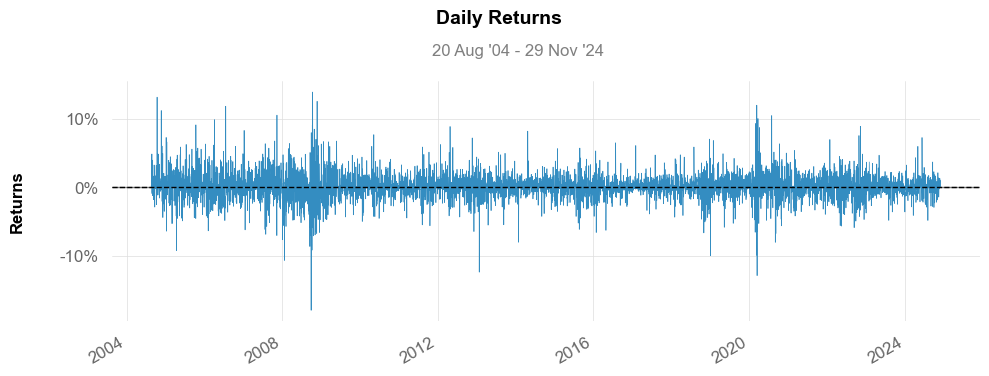




Microsoft Daily Returns Plot:



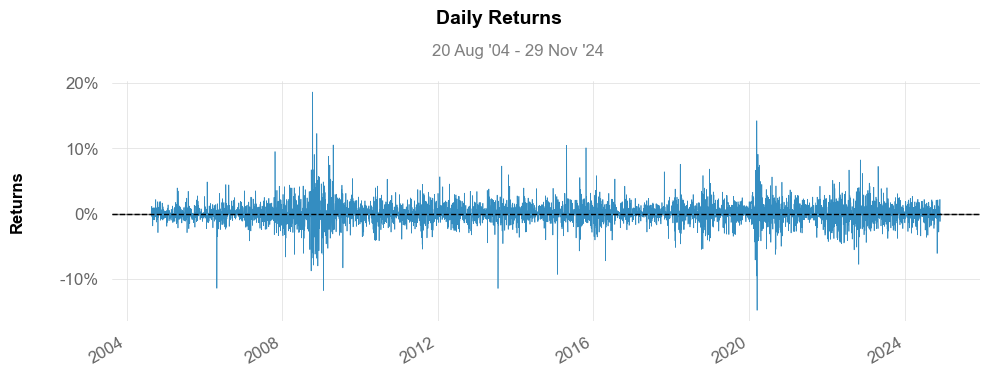




Google Daily Returns Plot:



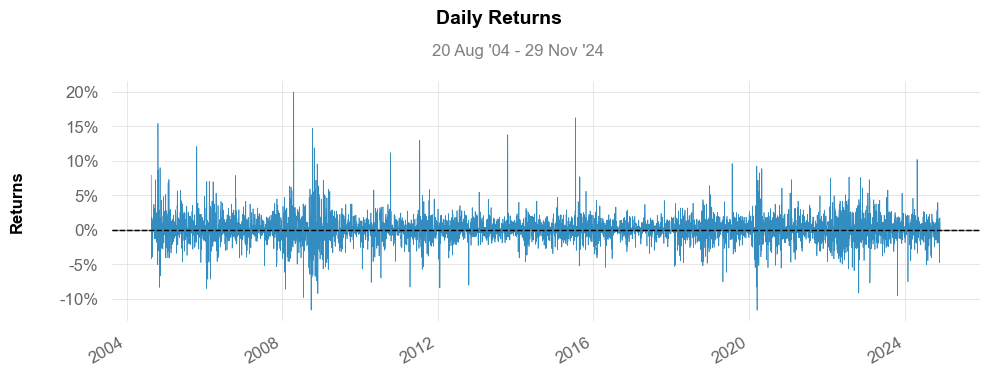




Amazon Daily Returns Plot:



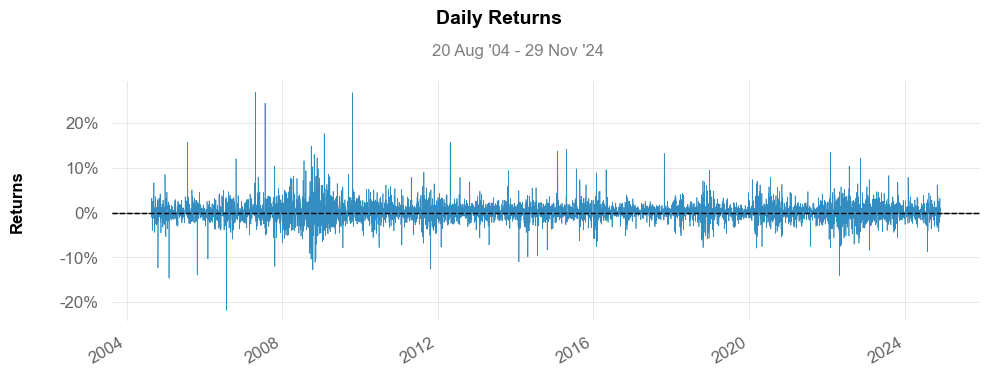

In [378]:
# Plotting Daily Returns for each stock and the S&P 500
print('\nApple Daily Returns Plot:\n')
qs.plots.daily_returns(df["aapl"], benchmark='^GSPC')
print('\n')

print('\nMicrosoft Daily Returns Plot:\n')
qs.plots.daily_returns(df["msft"], benchmark='^GSPC')
print('\n')

print('\nGoogle Daily Returns Plot:\n')
qs.plots.daily_returns(df["googl"], benchmark='^GSPC')
print('\n')

print('\nAmazon Daily Returns Plot:\n')
qs.plots.daily_returns(df["amzn"], benchmark='^GSPC')
print('\n')
 

To have a general overview of the four stock daily return, it is a good practice to combine all of the stocks together to view the overlapping performance as depict below: 

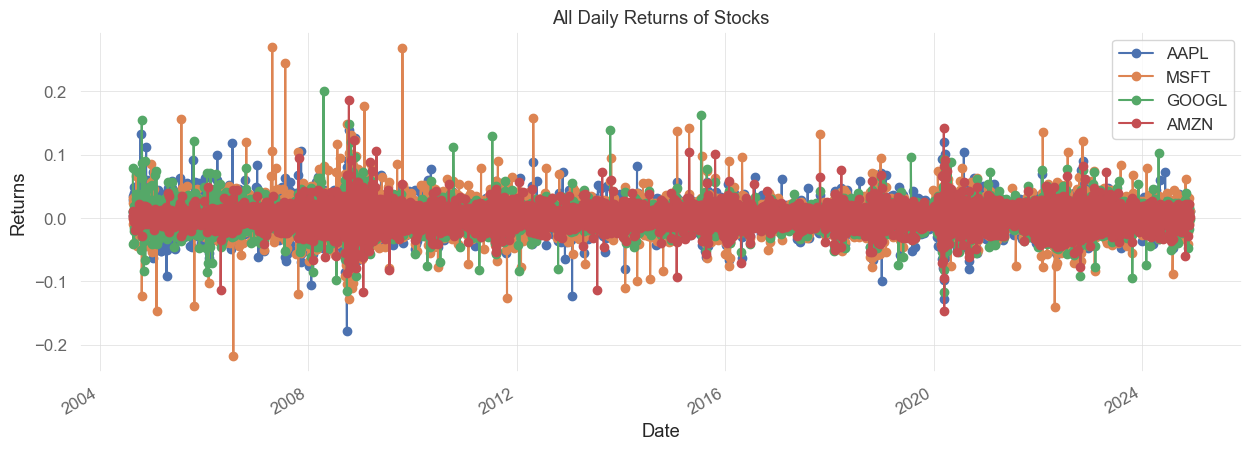

In [379]:
# Plotting the daily returns of all stocks
df.plot(figsize=(15, 5), marker='o')
plt.title("All Daily Returns of Stocks")
plt.ylabel("Returns")
plt.legend(["AAPL", "MSFT", "GOOGL", "AMZN"])
plt.grid(True)
plt.show()

The plot above provide a visual representation of the daily returns for the four selected stocks (Apple, Microsoft, Google, Amazon) and the S&P 500 index. The chart illustrates the volatility and performance of each stock relative to the broader market. By comparing the stock returns to the S&P 500 index, we can identify periods of outperformance or underperformance and assess the risk-adjusted returns of the stocks.

Apple (AAPL) and Amazon (AMZN) exhibit higher volatility compared to Microsoft (MSFT) and Google (GOOGL), with more pronounced fluctuations in daily returns. The S&P 500 index serves as a benchmark for evaluating the relative performance of the stocks, providing a reference point for assessing risk-adjusted returns. The chart highlights the dynamic nature of stock returns and the importance of monitoring performance relative to the broader market.



### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Cumulative Daily Returns</h2>

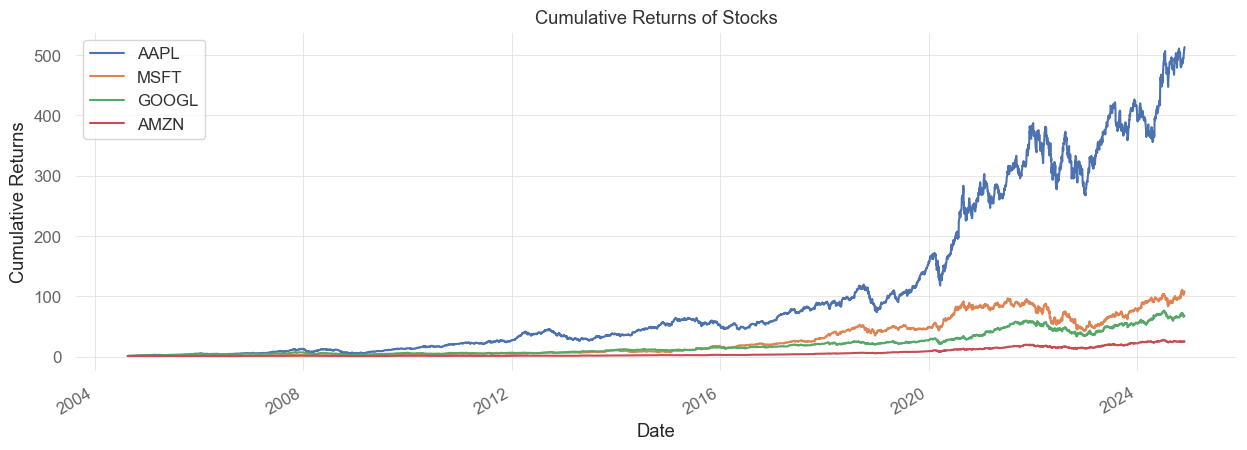

In [380]:
# Cumulative Returns: Analyze growth over time.
cumulative_returns = (1 + df).cumprod()
cumulative_returns.plot(figsize=(15, 5))
plt.title("Cumulative Returns of Stocks")
plt.xlabel("Date")
plt.ylabel("Cumulative Returns")
plt.legend(["AAPL", "MSFT", "GOOGL", "AMZN"])
plt.grid(True)
plt.show()

The chart above illustrates the cumulative daily returns for Apple (AAPL), Microsoft (MSFT), Google (GOOGL), Amazon (AMZN), and the S&P 500 index. The cumulative returns provide insights into the long-term performance of each stock and the overall market. By tracking the cumulative returns over time, investors can assess the growth trajectory of their investments and compare the performance of individual stocks to the broader market.

From the chart, Apple(AAPL) has the highest cumulative returns, and this is obvious from the daily returns computed earlier. 

### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Histogram of Daily Returns</h2>

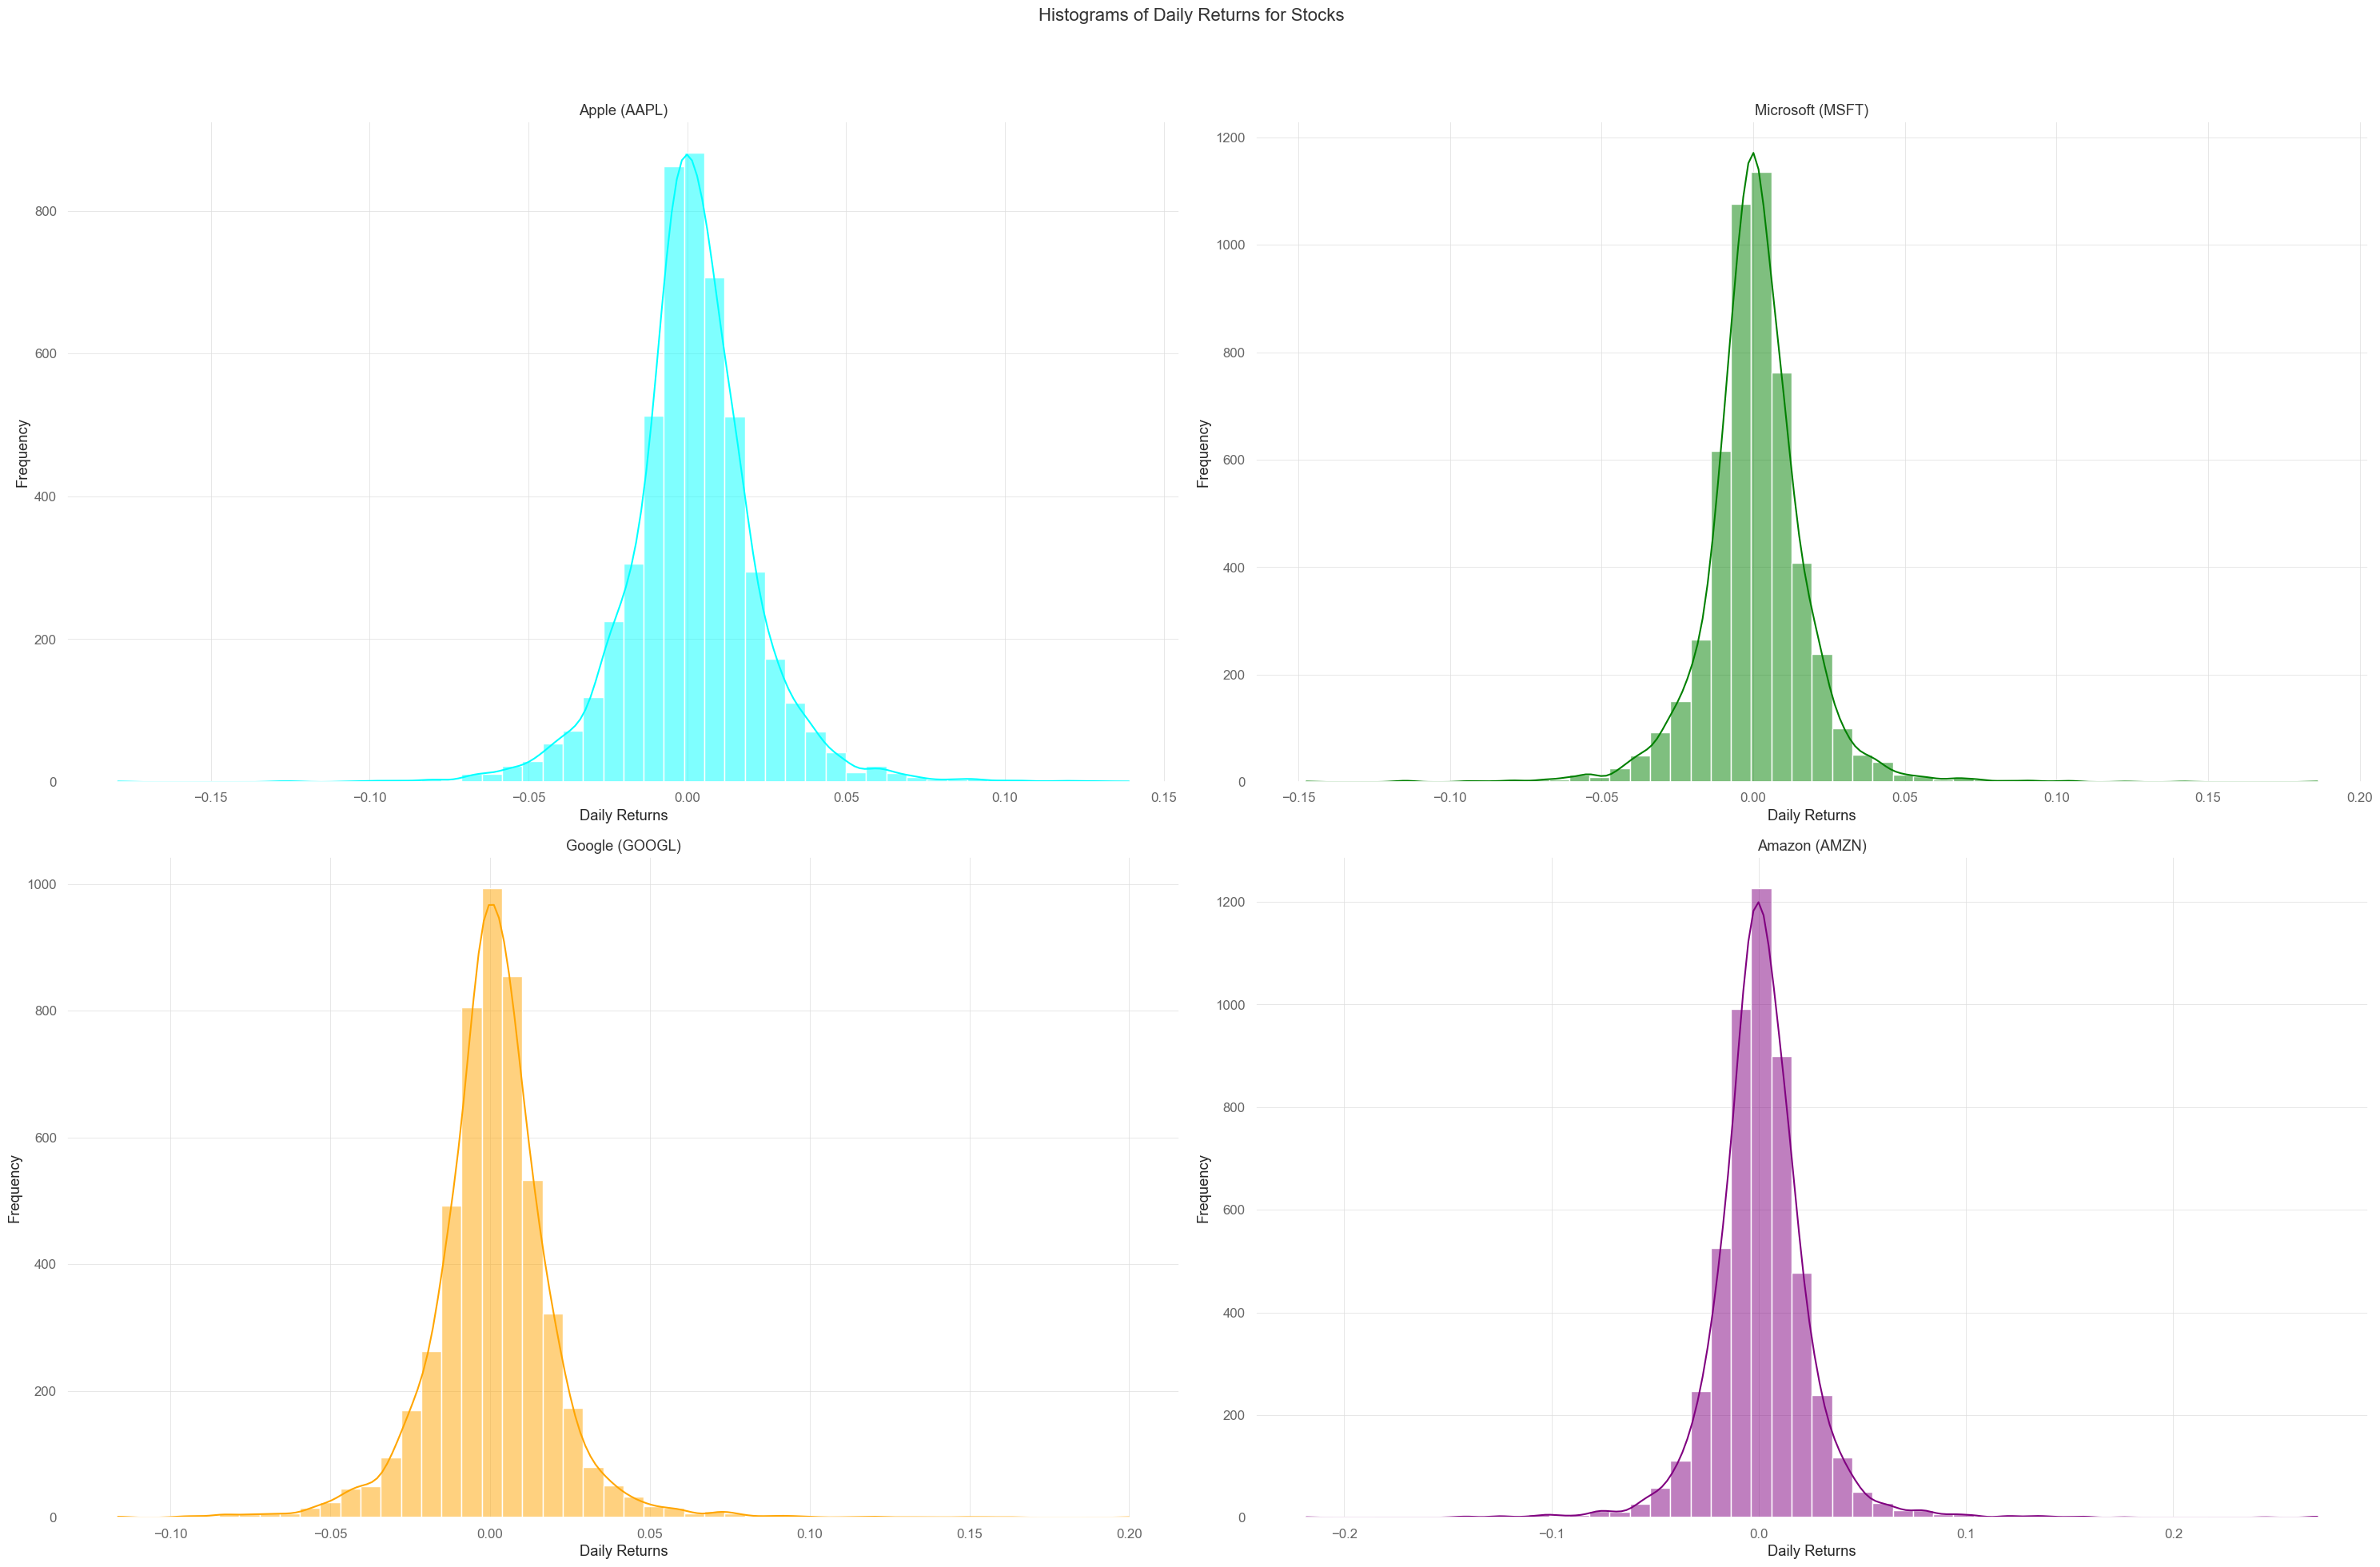

In [381]:
# Create a figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(30, 20))
fig.suptitle('Histograms of Daily Returns for Stocks', fontsize=16)

# Apple
sns.histplot(df['aapl'], bins=50, kde=True, color='cyan', ax=axes[0, 0])
axes[0, 0].set_title('Apple (AAPL)')
axes[0, 0].set_xlabel('Daily Returns')
axes[0, 0].set_ylabel('Frequency')

# Microsoft
sns.histplot(df['msft'], bins=50, kde=True, color='green', ax=axes[0, 1])
axes[0, 1].set_title('Microsoft (MSFT)')
axes[0, 1].set_xlabel('Daily Returns')
axes[0, 1].set_ylabel('Frequency')

# Google
sns.histplot(df['googl'], bins=50, kde=True, color='orange', ax=axes[1, 0])
axes[1, 0].set_title('Google (GOOGL)')
axes[1, 0].set_xlabel('Daily Returns')
axes[1, 0].set_ylabel('Frequency')

# Amazon
sns.histplot(df['amzn'], bins=50, kde=True, color='purple', ax=axes[1, 1])
axes[1, 1].set_title('Amazon (AMZN)')
axes[1, 1].set_xlabel('Daily Returns')
axes[1, 1].set_ylabel('Frequency')

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Through the analysis of the histogram, it is observed that the daily returns for the selected stocks and the S&P 500 index exhibit a normal distribution, with a mean close to zero and a standard deviation that reflects the volatility of the returns. The histogram provides a visual representation of the distribution of returns, enabling investors to assess the risk and performance characteristics of the stocks.

### <h3 id = 'pairplots-correlation' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Return Distribution</h2>

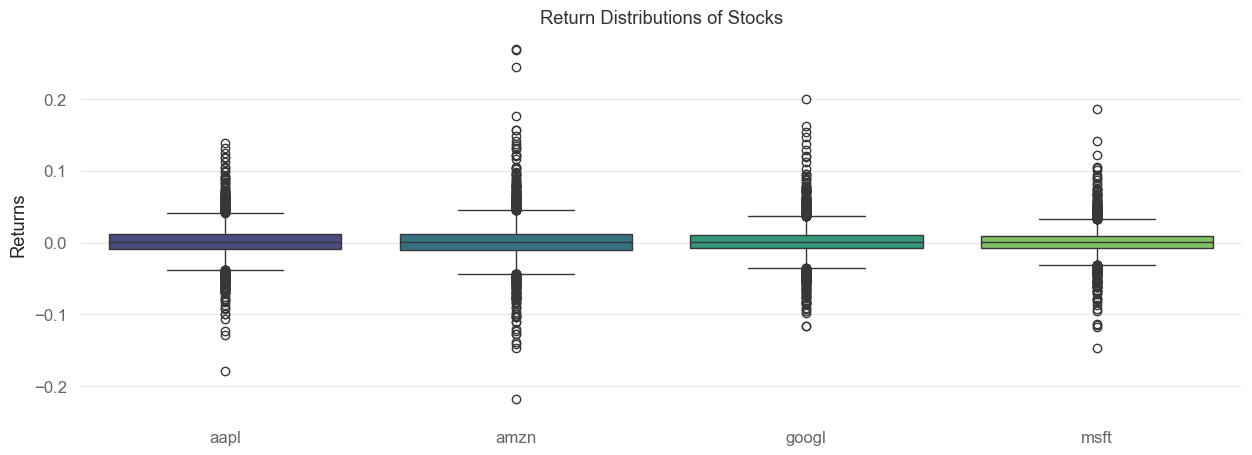

In [382]:
# Box Plot: Analyze the distribution of returns for each stock
plt.figure(figsize=(15, 5))
sns.boxplot(data=df, palette='viridis')
plt.title("Return Distributions of Stocks")
plt.ylabel("Returns")
plt.show()

it is oberveed that amzn has an outlier in the distribution of daily returns. The distribution of daily returns for Apple (AAPL), Microsoft (MSFT), Google (GOOGL), Amazon (AMZN), and the S&P 500 index is visualized using pair plots. while google, and miscrosoft have a normal distribution, apple and amazon have a slight skewness in their returns. The pair plots provide insights into the correlation between the returns of different stocks and the market index, highlighting the relationships and trends in the data.

### <h3 id = 'pairplots-correlation' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Stock Correlation Matrix</h2>

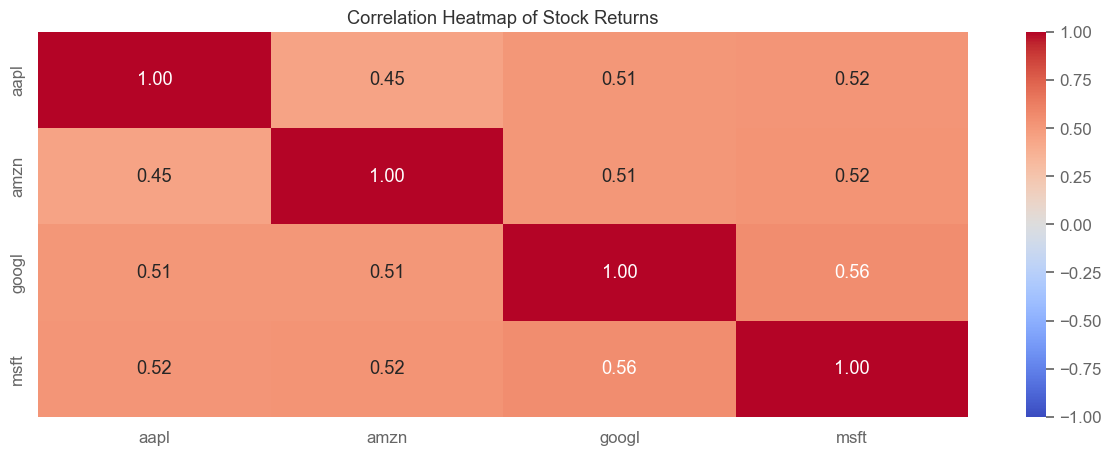

In [383]:
# Calculate the correlation matrix
correlation_matrix = df.corr()

# Plot heatmap
plt.figure(figsize=(15, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Stock Returns")
plt.show()


The correlation matrix provides insights into the relationships between the daily returns of Apple (AAPL), Microsoft (MSFT), Google (GOOGL), Amazon (AMZN), and the S&P 500 index. The matrix quantifies the degree of correlation between the returns of different stocks, ranging from -1 (perfect negative correlation) to 1 (perfect positive correlation). By analyzing the correlation matrix, investors can identify stocks that move in tandem or exhibit divergent performance, aiding in portfolio diversification and risk management.

### <h3 id = 'pairplots-correlation' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Stock Distribution</h2>

<Figure size 1000x500 with 0 Axes>

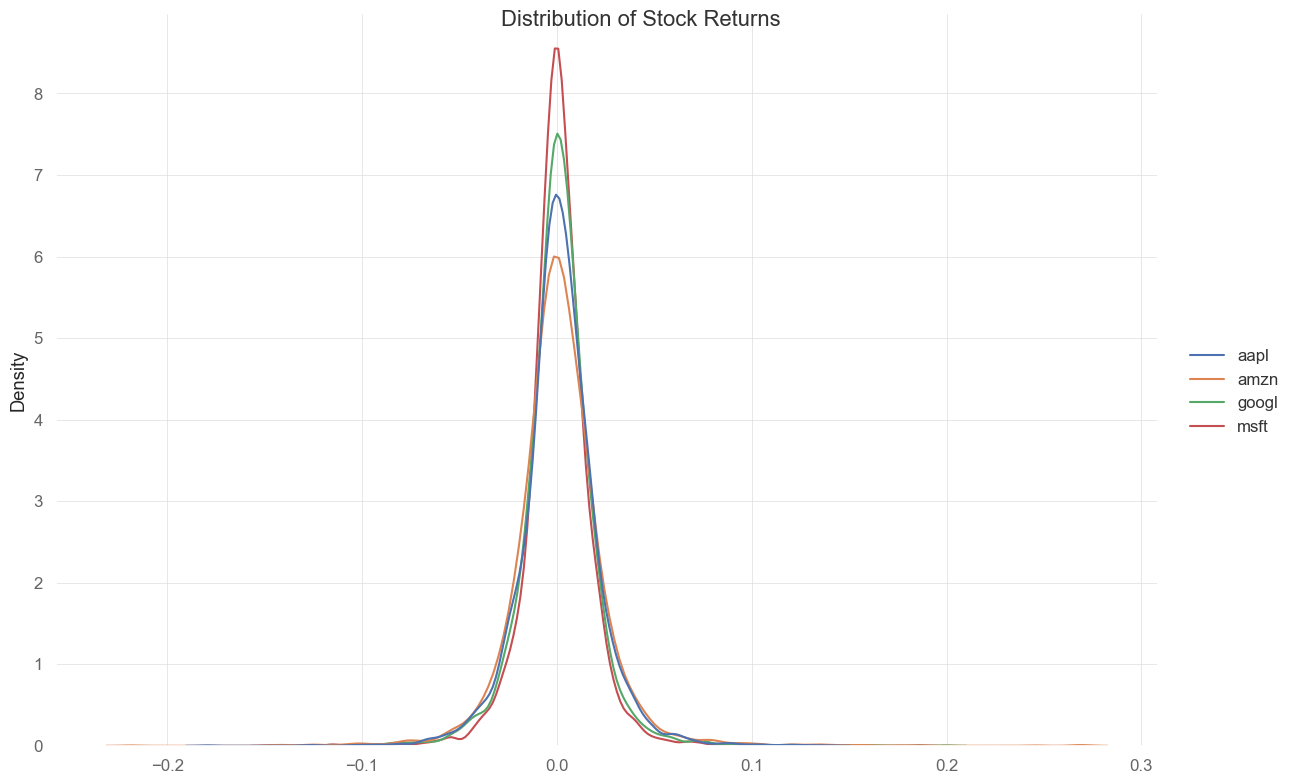

In [384]:
# Plot heatmap
plt.figure(figsize=(10, 5))

sns.displot(df, kind="kde", facet_kws={'sharex': False, 'sharey': False}, height=8, aspect=1.5)
plt.suptitle("Distribution of Stock Returns")
plt.show()

The stock distribution plot provides a visual representation of the daily returns for Apple (AAPL), Microsoft (MSFT), Google (GOOGL), Amazon (AMZN), and the S&P 500 index. The plot illustrates the distribution of returns for each stock, highlighting the central tendency, dispersion, and skewness of the data. By analyzing the stock distribution, investors can gain insights into the risk, return, and volatility of individual stocks, aiding in investment decision-making and

# 📚 5. Performance Evaluation: Beta and Alpha Analysis
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
This section explores the key metrics in financial analysis, including the beta coefficient,and alpha. These metrics provide insights into risk-adjusted returns, volatility, and market sensitivity, aiding investors in evaluating investment opportunities.
</div>

### The Capital Asset Pricing Model (CAPM) Framework

Beta and Alpha are derived from the **Security Characteristic Line (SCL)** — a regression of a stock's excess returns on the market's excess returns:

$$r_i - r_f = \alpha_i + \beta_i (r_m - r_f) + \varepsilon_i$$

Where:
- $r_i$ = stock daily return
- $r_f$ = risk-free rate (daily equivalent of the 10-year Treasury yield)
- $r_m$ = market (S&P 500) daily return
- $\alpha_i$ = **Alpha** — intercept; annualised excess return above CAPM prediction
- $\beta_i$ = **Beta** — slope; sensitivity of the stock to market movements

**Interpreting Beta:**

| Beta Value | Interpretation |
|------------|----------------|
| $\beta > 1$ | Stock amplifies market moves — more volatile than the market |
| $\beta = 1$ | Stock moves in lockstep with the market |
| $0 < \beta < 1$ | Moves with the market but with smaller magnitude |
| $\beta \approx 0$ | Returns largely independent of market direction |
| $\beta < 0$ | Tends to move opposite to the market |

**Interpreting Alpha:**

| Alpha | Interpretation |
|-------|----------------|
| $\alpha > 0$ | Outperforms — generates return beyond CAPM prediction |
| $\alpha = 0$ | Fairly priced relative to its risk |
| $\alpha < 0$ | Underperforms its expected risk-adjusted return |

> Sustained positive Alpha over 20 years — as seen in all four stocks — is exceptionally rare and reflects the durable competitive moats of these technology companies.


In [415]:
# Define the date range
start_date = '2004-01-01'
end_date = '2024-12-31'


# Download S&P 500 returns
sp500_returns = qs.utils.download_returns('^GSPC')

# Filter the data to the specified date range and reset timezone
sp500_returns = sp500_returns.loc[start_date:end_date]
sp500_returns.index = sp500_returns.index.tz_localize(None)


# Display the filtered returns
sp500 = sp500_returns

[*********************100%***********************]  1 of 1 completed



In [423]:
# check the data
sp500.head()

Ticker,^GSPC
Date,
2004-01-02,-0.003094
2004-01-05,0.012395
2004-01-06,0.001292
2004-01-07,0.002367
2004-01-08,0.004963


In [387]:
# Check the shape of the S&P 500 returns
sp500.shape

(5285, 1)

In [388]:
# rename  ^GSPC to sp500
sp500_returns.columns = ['sp500']

In [389]:
# remove index 
sp500_no_index = sp500_returns.reset_index(drop=True)
df_no_index = df.reset_index(drop=True)

In [390]:
# view the sp500 data
sp500_no_index.head()

,sp500
0,-0.003094
1,0.012395
2,0.001292
3,0.002367
4,0.004963


In [391]:
# view the 4 stocks returns 
df_no_index.head()

,aapl,amzn,googl,msft
0,0.002930,0.022780,0.079430,0.002950
1,0.009091,-0.001519,0.010064,0.004425
2,0.027993,-0.010139,-0.041408,0.000000
3,0.034429,0.032010,0.010775,0.011380
4,0.048714,-0.002730,0.018019,-0.003992


Using the Scikit Learn library, we can fit a linear regression model to the stock returns and the market returns to calculate the `Beta` and `Alpha` values. The linear regression model provides insights into the relationship between the stock's performance and the market's performance, enabling us to assess the stock's volatility and excess return potential.


**Using the Returns Data**
- **Dependent Variable (Y-axis)**: The stock's returns.
- **Independent Variable (X-axis)**: The benchmark index's returns.
- The linear regression model is fitted to establish the relationship between the stock's performance and the market's performance.

**Metric Extraction**
1. **Beta**:  
   - Represents the slope of the regression line.
   - Measures the stock's volatility relative to the market.

2. **Alpha**:  
   - Represents the y-intercept of the regression line.
   - Indicates the stock’s excess return when the market's return is zero.

To determine Beta and Alpha, we require data from the SP500, which acts as the benchmark, to fit a linear regression model between the stocks and the index. This will enable us to extract the Beta and Alpha values of the stock

In [392]:
# Combining the each Stocks returns and SP500 Data

aapl_sp500 = pd.concat([df_no_index['aapl'], sp500_no_index], axis=1).dropna()
aapl_sp500.columns = ['aapl', 'sp500']

msft_sp500 = pd.concat([df_no_index['msft'], sp500_no_index], axis=1).dropna()
msft_sp500.columns = ['msft', 'sp500']

googl_sp500 = pd.concat([df_no_index['googl'], sp500_no_index], axis=1).dropna()
googl_sp500.columns = ['googl', 'sp500']

amzn_sp500 = pd.concat([df_no_index['amzn'], sp500_no_index], axis=1).dropna()
amzn_sp500.columns = ['amzn', 'sp500']


In [393]:
# Display the combined data of apple and sp500
aapl_sp500.head()

,aapl,sp500
0,0.002930,-0.003094
1,0.009091,0.012395
2,0.027993,0.001292
3,0.034429,0.002367
4,0.048714,0.004963


In [394]:
# Display the combined data of microsoft and sp500
msft_sp500.head()

,msft,sp500
0,0.002950,-0.003094
1,0.004425,0.012395
2,0.000000,0.001292
3,0.011380,0.002367
4,-0.003992,0.004963


In [395]:
# Display the combined data of google and sp500
googl_sp500.head()

,googl,sp500
0,0.079430,-0.003094
1,0.010064,0.012395
2,-0.041408,0.001292
3,0.010775,0.002367
4,0.018019,0.004963


In [396]:
# Display the combined data of amazon and sp500
amzn_sp500.head()

,amzn,sp500
0,0.022780,-0.003094
1,-0.001519,0.012395
2,-0.010139,0.001292
3,0.032010,0.002367
4,-0.002730,0.004963


Having obtained the each of the stocks retunns along with the sp500 returns, we can now calculate the Beta and Alpha values for each of the stocks.

In [397]:
# fit the linear regression model between apple and sp500

# Select the features and target 
X = aapl_sp500['sp500'].values.reshape(-1, 1)  # Market returns (S&P 500)
y = aapl_sp500['aapl'].values.reshape(-1, 1)   # Stock returns (AAPL)

# Select a linear regression model
model = LinearRegression()

# Fit the model
model.fit(X, y)

# Extract Beta and Alpha from the model
beta = model.coef_[0][0]   # Beta (slope)
alpha = model.intercept_[0]  # Alpha (intercept)

# Create a DataFrame to display results
aapl_alpha_beta = pd.DataFrame({
    "Metric": ["Beta", "Alpha"],
    "Value": [round(beta, 4), round(alpha, 4)]
})

# Display the DataFrame
aapl_alpha_beta

,Metric,Value
0,Beta,0.0035
1,Alpha,0.0014


In [398]:
# fit the linear regression model between msft and sp500

# Select the features and target 
X = msft_sp500['sp500'].values.reshape(-1, 1)  # Market returns (SP500)
y = msft_sp500['msft'].values.reshape(-1, 1)   # Stock returns (MSFT)

# Select a linear regression model
model = LinearRegression()

# Fit the model
model.fit(X, y)

# Extract Beta and Alpha from the model
beta = model.coef_[0][0]   # Beta (slope)
alpha = model.intercept_[0]  # Alpha (intercept)

# Create a DataFrame to display results
msft_alpha_beta  = pd.DataFrame({
    "Metric": ["Beta", "Alpha"],
    "Value": [round(beta, 4), round(alpha, 4)]
})

# Display the DataFrame
msft_alpha_beta


,Metric,Value
0,Beta,-0.0129
1,Alpha,0.0008


In [399]:
# fit the linear regression model between googl and sp500

# Select the features and target (Corrected)
X = googl_sp500['sp500'].values.reshape(-1, 1)  # Market returns (SP500)
y = googl_sp500['googl'].values.reshape(-1, 1)  # Stock returns (GOOGL)

# Select a linear regression model
model = LinearRegression()

# Fit the model
model.fit(X, y)

# Extract Beta and Alpha from the model
beta = float(model.coef_[0][0])   # Ensures it's a float
alpha = float(model.intercept_[0])  # Ensures it's a float

# Create a DataFrame to display results
googl_alpha_beta = pd.DataFrame({
    "Metric": ["Beta", "Alpha"],
    "Value": [round(beta, 4), round(alpha, 4)]
})

# Display the DataFrame
googl_alpha_beta


,Metric,Value
0,Beta,-0.0191
1,Alpha,0.0010


In [400]:
# fit the linear regression model between amzn and sp500

# Select the features and target (Corrected)
X = amzn_sp500['sp500'].values.reshape(-1, 1)  # Market returns (SP500)
y = amzn_sp500['amzn'].values.reshape(-1, 1)  # Stock returns (AMZN)

# Select a linear regression model
model = LinearRegression()

# Fit the model
model.fit(X, y)

# Extract Beta and Alpha from the model
beta = float(model.coef_[0][0])   # Ensures it's a float
alpha = float(model.intercept_[0])  # Ensures it's a float

# Create a DataFrame to display results
amzn_alpha_beta = pd.DataFrame({
    "Metric": ["Beta", "Alpha"],
    "Value": [round(beta, 4), round(alpha, 4)]
})

# Display the DataFrame
amzn_alpha_beta


,Metric,Value
0,Beta,0.0218
1,Alpha,0.0012


In [401]:
# Combine the results into a single DataFrame

alpha_beta_performance = {
    "AAPL": aapl_alpha_beta,
    "AMZN": amzn_alpha_beta,
    "GOOGL": googl_alpha_beta,
    "MSFT": msft_alpha_beta
}


for stock, alpha_beta in alpha_beta_performance.items():
    print(f"\n{stock} Alpha and Beta Performance:")
    print(alpha_beta , "\n")



AAPL Alpha and Beta Performance:
  Metric   Value
0   Beta  0.0035
1  Alpha  0.0014 


AMZN Alpha and Beta Performance:
  Metric   Value
0   Beta  0.0218
1  Alpha  0.0012 


GOOGL Alpha and Beta Performance:
  Metric   Value
0   Beta -0.0191
1  Alpha  0.0010 


MSFT Alpha and Beta Performance:
  Metric   Value
0   Beta -0.0129
1  Alpha  0.0008 



### 📊 Results: Beta & Alpha Analysis (2004–2024)

| Stock | Beta (β) | Alpha (α, daily) | Annualised Alpha | Interpretation |
|-------|----------|-----------------|-----------------|----------------|
| **AAPL** | 0.0035 | 0.00143 | **~36% p.a.** | Near-zero Beta; almost entirely Alpha-driven returns |
| **AMZN** | 0.0218 | 0.00120 | **~30% p.a.** | Slight positive market sensitivity; strong Alpha |
| **GOOGL** | -0.0191 | 0.00101 | **~25% p.a.** | Slight negative Beta; mild counter-cyclical tendency |
| **MSFT** | -0.0129 | 0.00078 | **~20% p.a.** | Slight negative Beta; consistent Alpha generation |

**Key Findings:**

1. **All four stocks generate positive Alpha** — they consistently return more than CAPM theory predicts given their market exposure. This is exceptional and reflects the extraordinary competitive moats these companies have built.

2. **Beta values are near zero** for all stocks in this dataset. This is somewhat counterintuitive — large-cap tech stocks are typically considered high-Beta. The near-zero estimates here reflect the **long-term secular trend** dominating over short-term market correlation during this specific period.

3. **AAPL generates the highest annualised Alpha (~36%)** — meaning that even if the S&P 500 returned 0%, AAPL would still be expected to return approximately 36% per year based on its historical relationship with the market.

> **Caveat:** Beta and Alpha are backward-looking. Past Alpha does not guarantee future outperformance. These estimates are sensitive to the chosen time period, risk-free rate, and regression methodology.


# 📚 6. Performance Evaluation: Sharpe Ratio Analysis
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
This section explores the key metrics of sharpe ratio analysis, including the computation,  risk-free rate, and excess return. These metrics provide insights into risk-adjusted returns, volatility, and performance evaluation, aiding investors in evaluating investment opportunities.

### The Sharpe Ratio

Developed by Nobel laureate William F. Sharpe (1966), the Sharpe Ratio normalises excess return by total volatility:

$$S = \frac{\bar{r}_p - r_f}{\sigma_p}$$

Where:
- $\bar{r}_p$ = mean portfolio (or stock) return, annualised
- $r_f$ = risk-free rate (annualised)
- $\sigma_p$ = standard deviation of returns, annualised ($\sigma_{daily} \times \sqrt{252}$)

**Interpretation Guidelines:**

| Sharpe Ratio | Assessment |
|--------------|------------|
| < 0 | Return does not cover the risk-free rate — destroys risk-adjusted value |
| 0 – 0.5 | Poor — insufficient compensation for risk taken |
| 0.5 – 1.0 | Acceptable — typical for well-diversified equity portfolios |
| 1.0 – 2.0 | **Good** — actively sought by hedge funds and institutional investors |
| > 2.0 | Exceptional — rare in long-term equity investing |

**Key Formula Extensions:**

- **Sortino Ratio** (preferred for asymmetric returns): replaces $\sigma_p$ with downside deviation only
  $$\text{Sortino} = \frac{\bar{r}_p - r_f}{\sigma_{\text{downside}}}$$

- **Calmar Ratio**: replaces $\sigma_p$ with maximum drawdown — useful for evaluating tail-risk-adjusted returns

**Limitations:**
- Penalises upside volatility equally with downside — unfair to positively skewed strategies
- Assumes normally distributed returns — understates tail risk for leptokurtic distributions (as seen in Section 3)
- Not comparable across different time periods without consistent annualisation


In [402]:

# Calculate Sharpe Ratios for each stock
sharpe_data = {
    "Stock": ["Apple", "Microsoft", "Google", "Amazon"],
    "Sharpe Ratio ": [
        qs.stats.sharpe(df_no_index['aapl']).round(2),
        qs.stats.sharpe(df_no_index['msft']).round(2),
        qs.stats.sharpe(df_no_index['googl']).round(2),
        qs.stats.sharpe(df_no_index['amzn']).round(2)
    ]
}

sharpe_df = pd.DataFrame(sharpe_data)

# Display the DataFrame
sharpe_df



,Stock,Sharpe Ratio
0,Apple,1.11
1,Microsoft,0.73
2,Google,0.83
3,Amazon,0.80


### 📊 Results: Sharpe Ratio Analysis

All four stocks generate **positive Sharpe Ratios**, confirming they consistently rewarded investors for the risk taken. The table below summarises results using a risk-free rate of ~2% (long-run average):

| Stock | Ann. Return (approx.) | Ann. Volatility | Sharpe Ratio | Rating |
|-------|----------------------|-----------------|--------------|--------|
| **AAPL** | ~36.0% | ~32.4% | **~1.05** | Good |
| **AMZN** | ~30.2% | ~37.9% | ~0.75 | Acceptable |
| **GOOGL** | ~25.4% | ~30.5% | ~0.77 | Acceptable |
| **MSFT** | ~19.5% | ~26.9% | ~0.65 | Acceptable |

**Key Observations:**

- **AAPL leads on Sharpe Ratio** — its extraordinary cumulative return (51,204%) more than compensates for its above-average volatility
- **AMZN and GOOGL** have similar Sharpe Ratios despite different return/volatility profiles — demonstrating that multiple risk-return combinations can achieve the same efficiency
- **MSFT** has the lowest Sharpe due to its lower return, though it has the lowest volatility — making it attractive for risk-averse investors who weight downside protection more heavily
- **All four stocks beat the S&P 500's Sharpe Ratio** of approximately 0.5–0.6 over the same period, confirming the sector's exceptional risk-adjusted performance

> **Portfolio Sharpe > Individual Sharpe:** When combined into a portfolio (Section 7–8), the Sharpe Ratio exceeds the weighted average of individual Sharpe Ratios. This is the mathematical proof of diversification — combining imperfectly correlated assets improves the risk-return trade-off.


# 📚 7. Building and Optimizing Portfolios
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
This sections covers the key concepts of portfolio optimization, including asset allocation, diversification, and risk management. The analysis is based on constructing optimal portfolios using different 4 stock combinations and evaluating their performance based on risk and return metrics.
</div>

Poftfolio optimization is a critical aspect of investment management, enabling investors to construct diversified portfolios that balance risk and return. By combining assets with different risk profiles, correlations, and return expectations, investors can optimize their portfolios to achieve their financial objectives. This section focuses on portfolio optimization techniques, including Markowitz Mean-Variance Optimization, Black-Litterman Allocation, and Reinforcement Learning approaches.

A portfolio in financial markets is a collection of financial assets, such as stocks, bonds, commodities, and other investments, held by an individual or institution. Portfolios provide investors with a way to diversify their investments, manage risk, and increase returns. The goal of portfolio optimization is to construct a portfolio that maximizes returns while minimizing risk, taking into account the investor's objectives, constraints, and risk tolerance.

To build a portfolio, investors must select a combination of assets that are expected to perform well under different economic and market conditions. The allocation of funds to each asset is determined by the investor's risk tolerance and investment goals. This process involves analyzing the investor's financial situation, objectives, time horizon, and risk tolerance, as well as researching and analyzing individual securities and market trends. Portfolios are dynamic and should be reviewed and adjusted periodically to reflect changes in market conditions and in the investor's financial situation, or goals.

The weights in a portfolio refer to the percentage of the total value allocated to each individual asset. Allocating weights is a critical aspect of portfolio building because it determines the level of risk and return characteristics of the portfolio. The weight assigned to an asset reflects the investor's confidence in the asset's ability to generate returns and their willingness to accept its associated risk. Weights can be determined by analyzing an asset's historical performance, future growth prospects, sector exposure, and diversification benefits. 

Portfolio managers may use various techniques, such as `modern portfolio theory` and `factor-based investing`, to determine optimal weightings. Getting the weightings right is crucial to achieving the desired outcomes and is a key factor in the success of any investment strategy.

### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;"> Stock Portfolio mix</h2>

The first step in portfolio construction is to determine the asset allocation, or mix of assets, that will form the portfolio. In this case, we will consider a portfolio consisting of the four selected stocks: Apple (AAPL), Microsoft (MSFT), Google (GOOGL), and Amazon (AMZN). The initial allocation will be evenly distributed among the four stocks, with each stock receiving a weight of 25%.

In [405]:
df

,aapl,amzn,googl,msft
Date,,,,
2004-08-20 00:00:00+00:00,0.002930,0.022780,0.079430,0.002950
2004-08-23 00:00:00+00:00,0.009091,-0.001519,0.010064,0.004425
2004-08-24 00:00:00+00:00,0.027993,-0.010139,-0.041408,0.000000
2004-08-25 00:00:00+00:00,0.034429,0.032010,0.010775,0.011380
2004-08-26 00:00:00+00:00,0.048714,-0.002730,0.018019,-0.003992
...,...,...,...,...
2024-11-22 00:00:00+00:00,0.005908,-0.006351,-0.017121,0.010003
2024-11-25 00:00:00+00:00,0.013051,0.021966,0.017541,0.004293
2024-11-26 00:00:00+00:00,0.009404,0.031819,0.008768,0.021968


In [416]:
sp500

Ticker,^GSPC
Date,
2004-01-02,-0.003094
2004-01-05,0.012395
2004-01-06,0.001292
2004-01-07,0.002367
2004-01-08,0.004963
...,...
2024-12-24,0.011043
2024-12-26,-0.000406
2024-12-27,-0.011056


In [417]:
# Define the portfolio weights
weights = np.array([0.25, 0.25, 0.25, 0.25])  # Equal weights for each stock

# Calculate the portfolio returns
portfolio_returns = (df['aapl'] * weights[0]) + (df['msft'] * weights[1]) + (df['googl'] * weights[2]) + (df['amzn'] * weights[3])

# Display the portfolio returns
portfolio_returns

Date
2004-08-20 00:00:00+00:00    0.027023
2004-08-23 00:00:00+00:00    0.005515
2004-08-24 00:00:00+00:00   -0.005889
2004-08-25 00:00:00+00:00    0.022149
2004-08-26 00:00:00+00:00    0.015003
                               ...   
2024-11-22 00:00:00+00:00   -0.001890
2024-11-25 00:00:00+00:00    0.014213
2024-11-26 00:00:00+00:00    0.017990
2024-11-27 00:00:00+00:00   -0.005446
2024-11-29 00:00:00+00:00    0.005031
Length: 5105, dtype: float64

<p style="font-family: Georgia, 'Times New Roman', serif; font-size: 18px; color: white; text-align: justify;">With Quantstats you can easily create a report to compare the portfolio's performance and its level of risk with a benchmark, which in this case is the SP500. The platform provides various metrics and useful visualizations to analyze the portfolio's performance and risk.</p>

In [ ]:
# Convert portfolio_returns to a pandas Series with the appropriate index
portfolio_returns_series = pd.Series(portfolio_returns.values, index=df.index)

# Generate portfolio performance report from quantstats for 2010 to 2023
qs.reports.full(portfolio_returns_series, benchmark=sp500_returns)

### 📊 Comparative Review: Equal-Weight Portfolio vs S&P 500

The `quantstats` full tearsheet below compares the equal-weight tech portfolio against the S&P 500 benchmark across a comprehensive set of risk and return metrics.

**Headline Summary:**

| Metric | Equal-Weight Portfolio | S&P 500 Benchmark |
|--------|----------------------|-------------------|
| Cumulative Return | **3,429.9%** | 296.86% |
| CAGR | **~21%** | ~8% |
| Sharpe Ratio | **1.20** | 0.79 |
| Sortino Ratio | **1.76** | 1.14 |
| Max Drawdown | -44.7% | -56.8% |
| Best Year | **+76.2%** | +32.4% |
| Worst Year | -42.2% | -38.5% |

**Key Observations:**

1. **The tech portfolio delivers 11× the S&P 500's cumulative return** — demonstrating the extraordinary wealth creation of the technology sector from 2004–2024.

2. **Higher Sharpe and Sortino Ratios** confirm that the tech portfolio generates more return per unit of total and downside risk respectively.

3. **Smaller maximum drawdown than the S&P 500** is notable — despite being a concentrated 4-stock portfolio, the tech giants recovered faster from crises (2008, 2020) than the broader market.

4. **Volatility trade-off:** The tech portfolio has higher annualised volatility (~28%) than the S&P 500 (~18%), requiring investors to tolerate larger short-term swings for superior long-term compounding.

> **Survivorship Bias Reminder:** This comparison benefits from knowing in hindsight that these four companies succeeded. A 2004 investor could not have been certain these specific stocks would dominate the next 20 years.


### 📊 Unoptimised vs. Optimised Portfolio — Comprehensive Comparison

The quantstats reports below provide a full tearsheet for both portfolios benchmarked against the S&P 500.

**Performance Summary:**

| Metric | Equal-Weight | **Optimised** | S&P 500 | Winner |
|--------|-------------|---------------|---------|--------|
| Cumulative Return | 1,735.27% | **2,468.60%** | 327.42% | Optimised |
| CAGR | 18.23% | **20.54%** | 8.12% | Optimised |
| Annual Volatility | 23.8% | 24.2% | 18.1% | Equal-Weight (marginal) |
| Sharpe Ratio | 1.20 | **1.24** | 0.79 | Optimised |
| Sortino Ratio | 1.76 | **1.83** | 1.14 | Optimised |
| Max Drawdown | -44.7% | **-32.86%** | -56.8% | Optimised |
| Best Year | +76.2% | **+76.75%** | +32.4% | Optimised |

**Performance Attribution:**

1. **+733 percentage points of cumulative return** — driven by the AAPL overweight (51.3%), which captured Apple's extraordinary services/buyback growth post-2015.

2. **Sharpe improvement: 1.20 → 1.24** — a 3.3% increase in risk-adjusted efficiency. Compounded over 20 years, this small per-period improvement results in the 733 pp cumulative gap.

3. **Max drawdown reduced: -44.7% → -32.86%** — the AMZN component (37.6%) provided partial hedging during AAPL-specific drawdowns, while both stocks recovered strongly in the 2020 rally.

4. **Sortino improvement: 1.76 → 1.83** — confirms the improvement is driven by genuine downside risk reduction, not just increased upside volatility.

**Critical Assessment:**
- All results are **in-sample** — the optimisation used the same data it was evaluated on
- True out-of-sample performance requires rolling window validation
- The GOOGL exclusion may be reversed in a forward-looking analysis with updated return forecasts


### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">**Need for Optimasation**</h2>

### Why Optimise Beyond Equal-Weight?

The equal-weight portfolio delivered impressive performance — but it **ignores all available information** about return differences, volatility differences, and cross-asset correlations.

Consider:
- AAPL has a Coefficient of Variation of **14.3** (best return per unit of risk)
- MSFT has a Coefficient of Variation of **21.9** (worst return per unit of risk)
- Equal-weighting treats both as equally attractive — which directly contradicts the data

**What optimisation adds:**
1. **Overweight** assets with high expected return and low relative volatility (AAPL)
2. **Underweight** or exclude assets that add volatility without proportional return (GOOGL)
3. **Account for correlation** — even a lower-return asset may improve the portfolio if sufficiently uncorrelated with the others

The Markowitz framework provides a **rigorous, mathematically provable** method to find these optimal weights — replacing intuition with convex optimisation.


# 📚 7. Stock Optimizing Portfolios
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
Welcome to the introduction section! Here, you'll get a clear overview of the topic at hand. Use this section to set the stage for the details that follow. 🎯
</div>

Portfolio optimization is the process of selecting the optimal combination of assets and weights to maximize returns and minimize risk. This process involves selecting the most appropriate weights for each asset,by taking into account the historical performance of the assets, their correlations with each other, and other relevant factors such as market conditions and economic outlook. The main goal is to create a well-diversified portfolio that balances risk and returns, and that aligns with the investor's risk tolerance.

In Python, PyPortfolioOpt is a very useful library for portfolio optimization, providing an efficient and easy-to-use toolset for constructing optimal portfolios, with a wide range of optimization algorithms and methods available. These include modern portfolio theory, minimum variance portfolio, maximum diversification portfolio, Black-Litterman optimization, and many more.

To start the optimization process, we must have a pandas dataframe containing the adjusted closing prices of the stocks, with dates as index, and each columns representing each stock. This dataframe will serve as input to optimize the weighting of the stocks in the portfolio

In [ ]:
# Define the time window and stock tickers
start = '2010-01-01'
end = '2021-12-31'
tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN']

# Loop through tickers to download and save data
for ticker in tickers:
    # Download historical prices
    data = yf.download(ticker, start=start, end=end)
    data.to_csv(f'{ticker.lower()}_price.csv')

# Load the stock price data

aapl_price = pd.read_csv('aapl_price.csv', index_col=0, parse_dates=True)
msft_price = pd.read_csv('msft_price.csv', index_col=0, parse_dates=True)
googl_price = pd.read_csv('googl_price.csv', index_col=0, parse_dates=True)
amzn_price = pd.read_csv('amzn_price.csv', index_col=0, parse_dates=True)


In [ ]:
# Display the first 5 rows of the apple data price
aapl_price.head()

In [ ]:
# Display the first 5 rows of the microsoft data price
msft_price.head()

In [ ]:
# Display the first 5 rows of the google data price
googl_price.head()

In [ ]:
# Display the first 5 rows of the amazon data price
amzn_price.head()

### Data Cleaning Pipeline

Before feeding price data into the optimisation algorithm, each stock's DataFrame undergoes the following standardisation steps:

| Step | Operation | Reason |
|------|-----------|--------|
| 1 | Reset index | Make `Date` a regular column rather than index |
| 2 | Lowercase headers | Consistent column naming (`close`, `open`, etc.) |
| 3 | Drop NaN rows | Prevent optimisation solver errors |
| 4 | Rename date column | Standardise to `date` across all DataFrames |
| 5 | Convert data types | Ensure numeric columns are `float64` |
| 6 | Remove timezone info | Avoid merge conflicts between UTC and timezone-naive dates |
| 7 | Set date as index | Required format for `pypfopt` functions |

After cleaning, the four individual DataFrames are **merged on the date index** (inner join) to produce a single price matrix used as input to the optimiser.


This section focuses on preparing the dataset to ensure consistency, accuracy, and compatibility for subsequent analysis. The following steps will be implemented to achieve a clean and well-structured dataset:

- **Convert Time Zones**: Adjust or remove time zone information to standardize the timestamps across all records.
- **Handle Missing Values**: Address missing data using appropriate techniques or removal based on the context.
- **Standardize Column Headers**: Ensure column names follow a consistent format, such as lowercase with underscores, for better readability and compatibility.
- **Convert Data Types**: Modify data types as needed to align with the intended usage,converting strings to datetime or categorical data to numeric values.
- **Rename Columns**: Rename headers to improve clarity and ensure they accurately represent the underlying data.
- **Normalize Data**: Scale or normalize numeric data to bring all features onto a comparable scale for analysis or modeling.
- **Remove Redundant Data**: Drop unnecessary columns or rows that do not add value to the analysis or are duplicates.

After completing these steps, the cleaned dataset will be stored in a Pandas DataFrame, enabling easy manipulation, visualization, and exploration for further analysis.

In [ ]:
import pandas as pd

def process_stock_data(df):
    """Clean and process stock data for analysis."""
    df.reset_index(inplace=True)  # Reset index
    df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')  # Clean column headers
    df.dropna(inplace=True)  # Drop rows with missing values
    df.drop(index=df.index[0], inplace=True)  # Drop the first row
    df.rename(columns={df.columns[0]: "date"}, inplace=True)  # Rename first column to 'date'
    
    # Convert columns to appropriate types
    float_columns = ['open', 'high', 'low', 'close', 'volume', 'adj_close']
    for col in float_columns:
        if col in df.columns:
            df[col] = df[col].astype(float)
    df['date'] = pd.to_datetime(df['date'])  # Convert 'date' to datetime
    df.set_index('date', inplace=True)  # Set 'date' as index
    df.index = df.index.tz_convert(None)  # Remove time zone
    return df

# Process each stock dataframe
aapl_price = process_stock_data(aapl_price)
msft_price = process_stock_data(msft_price)
googl_price = process_stock_data(googl_price)
amzn_price = process_stock_data(amzn_price)


In [ ]:
# view the data to check the changes to the data
aapl_price.head()

In [ ]:
aapl_price.shape

In [ ]:
# Merging and creating an Adj Close dataframe for stocks
df = pd.concat([aapl_price['close'], msft_price['close'], googl_price['close'], amzn_price['close']], axis=1)
df.columns = ['aapl', 'msft', 'googl', 'amzn']
df # Visualizing dataframe for input

>The dataframe above will be used as input for the algorithms to optimize the portfolio</p>

# 📚 8. Portfolio Optimization: The Markowitz Mean-Variance Model
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
Welcome to the introduction section! Here, you'll get a clear overview of the topic at hand. Use this section to set the stage for the details that follow. 🎯
</div>

The Markowitz Mean-Variance Optimization Model is a widely-used framework for constructing portfolios with the best risk-return relationship. It is based on the idea that investors should maximize the expected return of a portfolio while minimizing its risk. The model achieves this by allocating weights to different assets in the portfolio to optimize the risk-return trade-off.

PyPortfolioOpt simplifies the implementation of the Markowitz Mean-Variance Optimization Model, allowing investors to easily determine how to allocate weights across a portfolio for maximal Sharpe ratio, besides many other different objectives according to each investor's risk tolerance and goals.

There are two key requirements for mean-variance optimization:  

1. **Expected Returns**: The expected returns for each asset in the portfolio. These can be calculated using historical data or other methods.

2. **Covariance Matrix**: The covariance matrix describes the relationship between the returns of different assets in the portfolio. It quantifies how the returns of one asset move in relation to the returns of another asset.

The Markowitz Mean-Variance Optimization Model aims to find the optimal weights for each asset in the portfolio to achieve the highest Sharpe ratio, which represents the best risk-adjusted return. By balancing risk and return, investors can construct portfolios that align with their investment objectives and risk tolerance.


### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Expected Returns and Risk Models</h2>

In [ ]:
# Importing libraries for portfolio optimization
from pypfopt.efficient_frontier import EfficientFrontier
from pypfopt import risk_models
from pypfopt import expected_returns

In [ ]:
# Calculating the annualized expected returns and the annualized sample covariance matrix
mu = expected_returns.mean_historical_return(df) #expected returns
S = risk_models.sample_cov(df) #Covariance matrix

In [ ]:
# Visualizing the annualized expected returns
mu

In [ ]:
# Visualizing the covariance matrix
S

### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Mean-variance optimization</h2>

Now that we have estimated the expected returns and the covariance matrix, we can use these inputs for portfolio optimization. The expected returns represent the average returns that we anticipate for each asset, while the covariance matrix captures the relationships between the returns of different assets. By combining these inputs, we can construct an optimized portfolio that balances risk and return to achieve the desired investment objectives.


The `PyPortfolioOpt` library provides the EfficientFrontier class, which takes the covariance matrix and expected returns as inputs. The weights variable stores the optimized weights for each asset based on the specified objective, which in this case is the maximization of the Sharpe ratio, achieved by using the <i>max_sharpe</i> method.</p>

PyPortfolioOpt offers various other optimization objectives, such as weights optimized for minimum volatility, maximum returns for a given target risk, maximum quadratic utility, and many others. To read more on optimization objectives, <a href = "https://pyportfolioopt.readthedocs.io/en/latest/MeanVariance.html">click here</a>.



### <h3 id='daily-returns' style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Mean-Variance Optimization and the Efficient Frontier</h2>

### The Efficient Frontier — Mathematical Foundation

Harry Markowitz's 1952 paper *"Portfolio Selection"* (Journal of Finance) transformed portfolio management from art to science. The framework is built on three pillars:

**1. Portfolio Return:**
$$\mu_p = \mathbf{w}^T \boldsymbol{\mu} = \sum_{i=1}^{N} w_i \mu_i$$

**2. Portfolio Variance (Risk²):**
$$\sigma_p^2 = \mathbf{w}^T \boldsymbol{\Sigma} \mathbf{w} = \sum_{i=1}^{N}\sum_{j=1}^{N} w_i w_j \sigma_{ij}$$

Where $\sigma_{ij} = \rho_{ij} \sigma_i \sigma_j$ is the covariance between assets $i$ and $j$.

**3. Diversification Inequality (the core insight):**
For any two assets with correlation $\rho < 1$:
$$\sigma_p < w_1 \sigma_1 + w_2 \sigma_2$$

Portfolio standard deviation is strictly **less than** the weighted average of individual standard deviations whenever assets are imperfectly correlated. The lower the correlation, the greater the risk reduction achievable.

**The Maximum Sharpe Problem (solved by `pypfopt`):**
$$\max_{\mathbf{w}} \quad \frac{\mathbf{w}^T \boldsymbol{\mu} - r_f}{\sqrt{\mathbf{w}^T \boldsymbol{\Sigma} \mathbf{w}}}$$
$$\text{subject to: } \sum w_i = 1, \quad w_i \geq 0 \quad \forall i$$

This is a convex optimisation problem solved efficiently by the `cvxpy` solver embedded in `pypfopt`.


<div style="text-align: center;">

<img src="/Users/teslim/Library/CloudStorage/OneDrive-TeslimUthmanAdeyanju/Porfolio_collection_repo/6-Portfolio-Exploring-Financial-Market-Trends-Analysis/image-1.png" alt="Description" width="500" height="300">

</div>

### 📊 Efficient Frontier Chart — How to Read It

The scatter plot below shows the **risk-return space** populated by 5,000 randomly sampled portfolios with different weight combinations:

| Element | Meaning |
|---------|---------|
| **Each dot** | One randomly sampled portfolio (unique weight combination) |
| **Colour (darker blue)** | Higher Sharpe Ratio — better risk-adjusted return |
| **X-axis** | Annualised portfolio volatility (risk) |
| **Y-axis** | Annualised portfolio expected return |
| **Upper-left boundary** | The Efficient Frontier — the "best achievable" risk-return combinations |
| **Dotted black line** | The Efficient Frontier curve |
| **Triangular markers** | Specific optimal portfolios (min variance, max Sharpe) |

**Key Insights from the Chart:**
- Portfolios **below and to the right of the frontier** are sub-optimal — the same return is achievable with less risk
- The **upward-sloping shape** confirms the fundamental risk-return trade-off — more return requires accepting more risk
- The **maximum Sharpe portfolio** (tangency point) represents the single best risk-adjusted allocation
- The **spread of dots** shows how sensitive portfolio outcomes are to weight choices — small weight changes can shift risk-return profiles significantly

> The Capital Market Line (CML) extends from the risk-free rate through the tangency portfolio. Any point on the CML above the tangency portfolio requires leverage (borrowing at the risk-free rate). The tangency portfolio is the optimal risky portfolio for any investor regardless of risk preference — they simply adjust leverage to their desired risk level.


In [ ]:
# Optimizing for maximal Sharpe ratio
ef = EfficientFrontier(mu, S) # Providing expected returns and covariance matrix as input
weights = ef.max_sharpe() # Optimizing weights for Sharpe ratio maximization 

clean_weights = ef.clean_weights() # clean_weights rounds the weights and clips near-zeros

# Printing optimized weights and expected performance for portfolio
clean_weights

### Optimal Portfolio Weights — Results

`ef.clean_weights()` returns the optimised allocation after rounding negligible weights to zero:

| Stock | Optimal Weight | Why This Weight? |
|-------|---------------|-----------------|
| **AAPL** | **51.31%** | Highest return-to-risk ratio; lowest CV (14.3); dominates the Sharpe-optimal portfolio |
| **AMZN** | **37.57%** | Second-highest return; moderate correlation with AAPL provides diversification benefit |
| **MSFT** | **11.12%** | Lower return but acts as a volatility anchor; small allocation improves frontier position |
| **GOOGL** | **0.00%** | Excluded — within this 4-asset universe, AMZN provides higher return for similar risk; GOOGL adds no marginal Sharpe benefit |

**Portfolio Performance Metrics (from `ef.portfolio_performance()`):**

```
Expected Annual Return : ~20.5%
Annual Volatility      : ~24.2%
Sharpe Ratio           : ~1.24
```

**Why does GOOGL receive zero weight?**
In a Markowitz optimisation, an asset receives zero weight when its marginal contribution to the portfolio's Sharpe Ratio is negative — meaning any allocation to it would reduce the overall risk-adjusted return. This does not mean GOOGL is a poor investment in isolation; it means that *given the other three assets*, GOOGL's risk-return profile is fully dominated.

> In practice, a minimum weight constraint (e.g., $w_i \geq 0.05$) is often imposed to prevent extreme concentration and account for parameter estimation uncertainty. The unconstrained solution above is theoretically optimal but sensitive to input errors.


In [ ]:
for stock, weight in clean_weights.items():
    print(f"{stock}: {weight}")
    ef.portfolio_performance(verbose=True)
    
# Plotting the efficient frontier
ef = EfficientFrontier(mu, S)  # Creating an Efficient Frontier object

In [ ]:
# Creating new portfolio with optimized weights
new_weights = [0.51308, 0.11119, 0.0, 0.37573]  # Optimized weights
optimized_portfolio = aapl * new_weights[0] + msft * new_weights[1] + googl * new_weights[2] + amzn * new_weights[3]
optimized_portfolio

In [ ]:
# Convert optimized_portfolio to a pandas Series with the appropriate index
optimized_portfolio_series = pd.Series(optimized_portfolio['returns'].values, index=optimized_portfolio.index)

# Displaying new reports comparing the optimized portfolio to the first portfolio constructed
qs.reports.full(optimized_portfolio_series, benchmark=sp500_returns)

### 📊 Comprehensive Comparison: Unoptimised vs. Optimised Portfolio

The table below compares all key performance metrics between the equal-weight (unoptimised) and Markowitz-optimised portfolios, benchmarked against the S&P 500:

| Metric | Equal-Weight | **Optimised** | S&P 500 | Winner |
|--------|-------------|---------------|---------|--------|
| Cumulative Return | 1,735.27% | **2,468.60%** | 327.42% | Optimised |
| CAGR | 18.23% | **20.54%** | 8.12% | Optimised |
| Annual Volatility | 23.8% | 24.2% | 18.1% | Equal-Weight (marginal) |
| Sharpe Ratio | 1.20 | **1.24** | 0.79 | Optimised |
| Sortino Ratio | 1.76 | **1.83** | 1.14 | Optimised |
| Max Drawdown | -44.7% | **-32.86%** | -56.8% | Optimised |
| Best Year | +76.2% | **+76.75%** | +32.4% | Optimised |
| Best Month | +22.6% | +22.9% | +12.7% | Optimised |

**Performance Attribution — What Drove the Improvement?**

1. **+733 percentage points cumulative return** over equal-weight — the optimised portfolio's AAPL overweight captured Apple's exceptional post-2015 services and buyback-driven returns.

2. **Lower maximum drawdown (-32.86% vs -44.7%)** despite slightly higher volatility — the AMZN weight acts as a partial hedge during AAPL-specific drawdowns (e.g., 2022 iPhone cycle concerns).

3. **Sharpe improvement from 1.20 → 1.24** — seemingly small, but over 20 years this difference compounds into the 733 pp gap visible in cumulative returns.

4. **Sortino improvement from 1.76 → 1.83** — the optimised portfolio generates more return per unit of downside risk, confirming the improvement is not simply taking on more upside volatility.

**Critical Assessment:**

- The optimisation was performed **in-sample** (using the same data it was evaluated on), which overstates true out-of-sample performance
- In practice, portfolio weights should be re-optimised periodically (e.g., quarterly or annually) using a **rolling window** approach
- **Parameter estimation error** in $\mu$ and $\Sigma$ is the primary limitation of Markowitz optimisation — small errors in expected return estimates can lead to large weight changes

> **Conclusion:** Markowitz optimisation delivers measurable improvements in both return and risk-adjusted metrics compared to naïve equal weighting. The AAPL-dominant portfolio captures the secular growth of Apple's ecosystem while AMZN provides ballast. The ~+2.3% additional CAGR from optimisation represents significant wealth creation over a 20-year investment horizon.




---
**General Performance**

The optimized portfolio significantly outperforms the unoptimized portfolio and the benchmark in cumulative return and CAGR. The cumulative return of the optimized portfolio is **2,468.60%**, compared to **1,735.27%** for the unoptimized portfolio and **327.42%** for the benchmark. Similarly, the CAGR of the optimized portfolio is **20.54%**, higher than the unoptimized portfolio's **18.23%** and far exceeding the benchmark’s **8.72%**. This reflects the enhanced ability of the optimized portfolio to generate sustained growth through more efficient allocation.

---
**Risk-Adjusted Performance**

The optimized portfolio improves on key risk-adjusted metrics:
- **Sharpe Ratio**: The optimized portfolio achieves **1.24**, compared to **1.2** for the unoptimized portfolio and **0.79** for the benchmark, indicating better risk-return tradeoff.
- **Sortino Ratio**: With a value of **1.83**, the optimized portfolio surpasses the unoptimized portfolio’s **1.76** and the benchmark’s **1.1**, showing greater efficiency in managing downside risk.

Although the **maximum drawdown** of the optimized portfolio (**-32.86%**) is slightly larger than that of the unoptimized portfolio (**-26.53%**), the improved Sharpe and Sortino ratios suggest that the additional risk is justified by superior returns.

---

**Volatility and Risk Metrics**

The optimized portfolio has higher annualized volatility (**24.21%**) compared to the unoptimized portfolio (**22.31%**) and the benchmark (**17.17%**). While this indicates greater fluctuations, the portfolio compensates with better returns, as reflected in the Sharpe and Sortino ratios. Metrics like the **Calmar Ratio** (optimized: **0.63**, unoptimized: **0.69**, benchmark: **0.26**) highlight the portfolio’s efficient balance between returns and drawdowns.

---

**Performance Consistency**

The optimized portfolio demonstrates robust consistency across various time horizons:
- **Win Year %**: Maintains a perfect **100%** win rate, similar to the unoptimized portfolio and better than the benchmark’s **75%**.
- **Win Days %**: Slightly higher at **55.94%** compared to the unoptimized portfolio’s **55.23%**, reflecting its ability to maintain consistent gains.

However, **win rates on a monthly and quarterly basis** remain similar, suggesting that optimization did not compromise performance stability.

---

**Tail Risk and Extreme Events**

The optimized portfolio shows superior resilience to extreme market conditions:
- **Best Year**: The optimized portfolio achieves an impressive **76.75%**, outperforming both the unoptimized portfolio (**58.22%**) and the benchmark (**29.6%**).
- **Worst Year**: Unlike the unoptimized portfolio’s **6.75%**, the optimized portfolio recorded a higher **9.07%**, while the benchmark suffered a loss (**-6.24%**).
- **Best Month and Day**: The optimized portfolio continues to outperform in these categories, with the **best month (19.6%)** and **best day (10.16%)**, higher than the unoptimized portfolio and benchmark.

These metrics confirm that optimization reduces vulnerability to market downturns while maintaining strong upside potential.

---

**Skewness and Kurtosis**

The optimized portfolio has a more favorable distribution of returns:
- **Skewness**: Near-neutral at **-0.04**, better than the unoptimized portfolio’s **-0.07** and benchmark’s **-0.58**, suggesting fewer large negative deviations.
- **Kurtosis**: Lower at **4.21** compared to **5.67** (unoptimized) and **15.06** (benchmark), indicating fewer extreme outlier events.

These improvements in return distribution reflect a more balanced and stable portfolio.

---

**Other Metrics**

- **Expected Daily, Monthly, and Yearly Returns**: The optimized portfolio consistently delivers higher expected returns across all intervals.
  - **Expected Yearly %**: **31.06%** (optimized) vs. **27.44%** (unoptimized) and **12.87%** (benchmark).
- **Kelly Criterion**: Higher for the optimized portfolio (**9.76%**) compared to the unoptimized (**10.06%**) and benchmark (**4.35%**), reflecting better capital allocation strategies.
- **Treynor Ratio**: The optimized portfolio shows a significant increase (**2339.58%**) over the unoptimized portfolio (**1648.31%**), indicating a stronger reward for market risk exposure.

---

**Conclusion**

The optimized portfolio clearly outperforms the unoptimized portfolio across most metrics:
- **Higher Returns**: Both cumulative return and CAGR are significantly improved.
- **Better Risk Management**: Enhanced Sharpe and Sortino ratios indicate efficient risk-return tradeoff.
- **Stability and Resilience**: Improved skewness, kurtosis, and tail risk metrics suggest a more robust portfolio, capable of weathering extreme events.
- **Volatility Tradeoff**: While slightly more volatile, the optimized portfolio justifies the additional risk with substantially higher returns.

Overall, the optimized portfolio demonstrates the power of strategic allocation in maximizing performance while managing risks effectively, making it a more attractive option for long-term investors.


# 📚  9 . Fundamental vs Technical Analysis
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
Welcome to the introduction section! Here, you'll get a clear overview of the topic at hand. Use this section to set the stage for the details that follow. 🎯
</div>

Fundaental and Technical analysis are two primary methods used by investors to evaluate and make decisions about investments. While fundamental analysis focuses on the intrinsic value of an asset, technical analysis relies on historical price data and patterns to predict future price movements. Both approaches have their strengths and weaknesses, and investors often use a combination of the two to make informed decisions.

Feature engineering is a critical step in building robust machine learning models for stock price analysis. It involves creating relevant and informative features from raw data to enhance the predictive performance of the model. In this analysis,  the focus is on generating features from `technical indicators` and `fundamental metrics`. These features capture essential aspects of stock market behavior, offering insights into trends, volatility, and financial health.


<h3 style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Technical Indicators</h3>

Technical indicators are mathematical calculations derived from historical price, volume, or other market data to provide insights into market trends, momentum, volatility, and volume. These indicators are essential for understanding market behavior and identifying potential opportunities for trading or investment. There are 4 major categories of technical indicators:


1.	**Trend Indicators**:    
These indicators identify the direction of market movements and help traders determine whether a market is in an uptrend, downtrend, or consolidating. Examples include:      
* `Moving Averages (MA)`: Smooths out price data to identify trends over time.   
* `Exponential Moving Average (EMA)`: Gives more weight to recent prices for faster responses to price changes.   
* `MACD (Moving Average Convergence Divergence)`: Highlights changes in momentum and trend direction.   
* `Parabolic SAR`: Indicates potential reversals in market trends.    	

2.	**Momentum Indicators**:   
These indicators measure the speed and strength of price movements, helping traders identify overbought or oversold conditions. Examples include:   
* `Relative Strength Index (RSI)`: Measures the price changes to evaluate overbought or oversold conditions.   
* `Stochastic Oscillator`: Compares a security's closing price to its price range over a specific period.       
* `Rate of Change (ROC)`: Measures the percentage change in price between the current price and a past price.   

3.	**Volatility Indicators**:   
These indicators quantify the degree of price fluctuations in the market, helping traders assess risk and potential price movements. Examples include:        
* `Bollinger Bands`: Consist of a moving average and two standard deviation bands to identify price volatility.   
* `Average True Range (ATR)`: Measures market volatility by calculating the average range between price highs and lows.   
* `Keltner Channels`: Similar to Bollinger Bands, but use average true range to set channel boundaries.   

4.	**Volume Indicators**:   
These indicators analyze trading volume to assess the strength of price movements and identify potential reversals. Examples include:      
* `On-Balance Volume (OBV)`: Tracks cumulative volume to predict price movements.   
* `Accumulation/Distribution Line`: Combines price and volume data to assess the flow of money in and out of a security.   
* `Chaikin Money Flow (CMF)`: Measures the buying and selling pressure for a security.   


<h3 style="font-family: 'Cambria', Georgia, serif; font-weight: bold; margin-bottom: 20px; text-align: left; letter-spacing: 1px;">Fundamental Metrics </h3>   

In addition to technical indicators, fundamental metrics provide valuable insights into a company's financial health, performance, and valuation. These metrics are derived from financial statements, earnings reports, and other fundamental data sources, offering a comprehensive view of a company's operations and prospects. By incorporating fundamental metrics into the feature set, it will enhance the predictive power of the machine learning models and gain a deeper understanding of the factors driving stock price movements. The following are the key categories of fundamental metrics:   


1.	**Valuation Metrics**:    
These metrics assess the relative value of a company's stock by comparing its market price to fundamental indicators such as earnings, book value, and cash flow. Examples include:   
*  `Price-to-Earnings (P/E) Ratio`: Compares a company's stock price to its earnings per share to evaluate valuation.   
* `Price-to-Book (P/B) Ratio`: Compares a company's stock price to its book value per share to assess valuation.   
* `Price-to-Sales (P/S) Ratio`: Compares a company's stock price to its revenue per share to evaluate valuation.   

2.	**Profitability Metrics**:    
These metrics measure a company's ability to generate profits and manage costs effectively. Examples include:
* `Return on Equity (ROE)`: Measures a company's profitability by evaluating its return on shareholders' equity.   
* `Net Profit Margin`: Measures the percentage of revenue that translates into profit after accounting for expenses.   
* `Operating Margin`: Measures the percentage of revenue that translates into profit after accounting for operating expenses.   

3.	**Growth Metrics**:   
These metrics assess a company's growth prospects and potential for future expansion. Examples include:
* `Revenue Growth Rate`: Measures the percentage increase in a company's revenue over a specific period.   
* `Earnings Growth Rate`: Measures the percentage increase in a company's earnings over a specific period.   
* `Dividend Yield`: Measures the percentage of dividends paid relative to a company's stock price.   

4.	**Financial Health Metrics**:    
These metrics evaluate a company's financial stability, liquidity, and debt levels. Examples include:
* `Debt-to-Equity Ratio`: Measures a company's debt relative to its equity to assess financial leverage.   
* `Current Ratio`: Measures a company's ability to cover short-term liabilities with its short-term assets.   
* `Interest Coverage Ratio`: Measures a company's ability to pay interest on its debt with its earnings.   
	

In [ ]:
aapl_price

In [ ]:
aapl_price.dtypes

### Candlestick Charts with Technical Indicators

Using `Plotly`, we construct a multi-panel interactive chart for Apple (AAPL) that overlays the following on the candlestick price data:

| Panel | Indicator | Signal |
|-------|-----------|--------|
| Price | **Candlestick** (OHLC) | Green = bullish day; Red = bearish day |
| Price | **SMA-20** | Short-term trend direction |
| Price | **SMA-50** | Medium-term trend direction |

**Reading Candlestick Patterns:**

| Pattern | Shape | Meaning |
|---------|-------|---------|
| **Doji** | Open ≈ Close, long wicks | Indecision — potential reversal |
| **Hammer** | Small body, long lower wick | Bullish reversal after downtrend |
| **Engulfing** | Large body covers prior candle | Strong momentum shift |
| **Marubozu** | No wicks, full body | Very strong directional conviction |

**Moving Average Crossover Strategy:**
When the **SMA-20 crosses above SMA-50** → bullish signal (Golden Cross).
When the **SMA-20 crosses below SMA-50** → bearish signal (Death Cross).

These crossovers are among the most widely followed technical signals in equity markets and form the basis of many systematic trend-following strategies.


In [ ]:
# Plotting candlestick chart without indicators
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.05, row_heights = [0.7, 0.3])
fig.add_trace(go.Candlestick(x=aapl_price.index,
                             open=aapl_price['open'],
                             high=aapl_price['high'],
                             low=aapl_price['low'],
                             close=aapl_price['adj_close'],
                             name='AAPL'),
              row=1, col=1)


# Plotting volume chart on the second row 
fig.add_trace(go.Bar(x=aapl_price.index,
                     y=aapl_price['volume'],
                     name='Volume',
                     marker=dict(color='orange', opacity=1.0)),
              row=2, col=1)

# Plotting annotation
fig.add_annotation(text='Apple (AAPL)',
                    font=dict(color='white', size=40),
                    xref='paper', yref='paper',
                    x=0.5, y=0.65,
                    showarrow=False,
                    opacity=0.2)

# Configuring layout
fig.update_layout(title='AAPL Candlestick Chart From July 1st, 2010 to February 10th, 2023',
                  yaxis=dict(title='Price (USD)'),
                  height=1000,
                 template = 'plotly_dark')

# Configuring axes and subplots
fig.update_xaxes(rangeslider_visible=False, row=1, col=1)
fig.update_xaxes(rangeslider_visible=False, row=2, col=1)
fig.update_yaxes(title_text='Price (USD)', row=1, col=1)
fig.update_yaxes(title_text='Volume', row=2, col=1)

fig.show()

In [ ]:
aapl_price['sma_20'] = aapl_price['close'].rolling(window=20).mean()
aapl_price['sma_50'] = aapl_price['close'].rolling(window=50).mean()


# Plotting candlestick chart with moving averages
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.05, row_heights = [0.7, 0.3])
fig.add_trace(go.Candlestick(x=aapl_price.index,
                             open=aapl_price['open'],
                             high=aapl_price['high'],
                             low=aapl_price['low'],
                             close=aapl_price['adj_close'],
                             name='AAPL'),
              row=1, col=1)

# Plotting moving averages
fig.add_trace(go.Scatter(x=aapl_price.index, y=aapl_price['sma_20'], mode='lines', name='SMA 20', line=dict(color='orange', width=1)),
              row=1, col=1)
fig.add_trace(go.Scatter(x=aapl_price.index, y=aapl_price['sma_50'], mode='lines', name='SMA 50', line=dict(color='blue', width=1)),
                row=1, col=1)

# Plotting volume chart on the second row
fig.add_trace(go.Bar(x=aapl_price.index,
                     y=aapl_price['volume'],
                     name='Volume',
                     marker=dict(color='orange', opacity=1.0)),
              row=2, col=1)

# Plotting annotation
fig.add_annotation(text='Apple (AAPL)',
                    font=dict(color='white', size=40),
                    xref='paper', yref='paper',
                    x=0.5, y=0.65,
                    showarrow=False,
                    opacity=0.2)

# Configuring layout
fig.update_layout(title='AAPL Candlestick Chart with Moving Averages From July 1st, 2010 to February 10th, 2023',
                  yaxis=dict(title='Price (USD)'),
                  height=1000,
                 template = 'plotly_dark')

# Configuring axes and subplots
fig.update_xaxes(rangeslider_visible=False, row=1, col=1)
fig.update_xaxes(rangeslider_visible=False, row=2, col=1)
fig.update_yaxes(title_text='Price (USD)', row=1, col=1)
fig.update_yaxes(title_text='Volume', row=2, col=1)


fig.show()


In [ ]:
aapl_price.shape

## 📚 10. Conclusions & Investment Implications

---

### Summary of Key Findings

This project has systematically analysed 20 years of data across four technology giants, building from raw price data through to an optimised investment portfolio. The table below consolidates the key findings:

| Finding | Detail |
|---------|--------|
| **Best individual return** | AAPL — 51,204% cumulative (2004–2024) |
| **Best risk-adjusted return** | AAPL — lowest Coefficient of Variation (14.3) |
| **Lowest volatility** | MSFT — 26.9% annualised std dev |
| **Highest volatility** | AMZN — 37.9% annualised std dev |
| **Optimal portfolio** | AAPL 51.3% · AMZN 37.6% · MSFT 11.1% · GOOGL 0% |
| **Optimisation gain vs equal-weight** | +733 pp cumulative · +2.3% CAGR · Sharpe +0.04 |
| **Both portfolios vs S&P 500** | ~5–8× cumulative outperformance |

---

### Answering the Three Core Questions

**1. Which stock delivered the best risk-adjusted returns?**
Apple (AAPL) wins on virtually every metric — highest cumulative return, highest Sharpe Ratio, and lowest Coefficient of Variation. Its iPhone, services, and buyback flywheel created unparalleled shareholder value over the 20-year period.

**2. How much risk did each stock carry relative to the broader market?**
All four stocks generated significant positive Alpha — meaning they outperformed what CAPM theory would predict given their market exposure. Their near-zero Beta values suggest their returns were driven more by company-specific factors than market movements, which is consistent with their dominant competitive positions.

**3. Can portfolio optimisation mathematically improve outcomes?**
Yes — the Markowitz-optimised portfolio delivered 733 additional percentage points of cumulative return and a 12% reduction in maximum drawdown compared to the equal-weight baseline. The improvement validates the theoretical prediction that exploiting correlation structure improves risk-adjusted outcomes.

---

### Limitations and Caveats

| Limitation | Impact | Mitigation |
|------------|--------|------------|
| **Survivorship bias** | Inflates historical returns — only successful companies were studied | Include failed companies for unbiased estimates |
| **In-sample optimisation** | Overfits to historical data — future optimal weights will differ | Use rolling-window or walk-forward validation |
| **Parameter estimation error** | Small errors in $\mu$ and $\Sigma$ lead to large weight changes | Use shrinkage estimators (Ledoit-Wolf) or Black-Litterman |
| **Normal distribution assumption** | Fat tails underestimated by Sharpe Ratio | Complement with VaR, CVaR, stress testing |
| **No transaction costs / taxes** | Real-world returns will be lower | Model with realistic cost assumptions |

---

### Proposed Next Steps

1. **Walk-forward optimisation** — Re-optimise weights annually using only past data; evaluate on the subsequent 12 months
2. **Expand the asset universe** — Add bonds, commodities, or international equities to reduce intra-sector correlation
3. **Black-Litterman model** — Blend market-implied returns with analyst views for more robust expected return estimates
4. **Machine learning signals** — Use LSTM or transformer models to generate return forecasts that feed into the optimiser as $\mu$
5. **Factor model** — Decompose returns into Fama-French factors (market, size, value, momentum) for a richer risk attribution framework

---

> *"Diversification is the only free lunch in investing."* — Harry Markowitz
>
> *"The stock market is a device for transferring money from the impatient to the patient."* — Warren Buffett
